<a href="https://colab.research.google.com/github/Pranattt/23BDS0241_EDA_project-/blob/main/23BDS0231_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

,rownames,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,1,0,100,1,24,14.500,0.495,-0.854,0.50,no,female,cauc,13,yes,afdc
2,2,1,90,3,19,6.000,0.520,-0.969,0.17,no,female,cauc,11,yes,afdc
3,3,0,106,4,17,8.377,-1.227,0.317,0.42,no,female,cauc,12,yes,afdc
4,4,0,114,2,29,6.000,-1.524,0.457,0.33,no,female,cauc,12,yes,afdc
5,5,11,115,1,26,8.500,0.173,-0.599,0.67,no,female,cauc,16,yes,afdc
6,6,3,102,1,22,6.000,-0.905,0.062,0.25,no,female,other,12,yes,afdc


[1] 996  15
'data.frame':	996 obs. of  15 variables:
 $ rownames : int  1 2 3 4 5 6 7 8 9 10 ...
 $ visits   : int  0 1 0 0 11 3 0 6 1 0 ...
 $ exposure : int  100 90 106 114 115 102 92 92 117 101 ...
 $ children : int  1 3 4 2 1 1 2 1 1 1 ...
 $ age      : int  24 19 17 29 26 22 24 21 21 24 ...
 $ income   : num  14.5 6 8.38 6 8.5 ...
 $ health1  : num  0.495 0.52 -1.227 -1.524 0.173 ...
 $ health2  : num  -0.854 -0.969 0.317 0.457 -0.599 0.062 0.202 -0.981 0.317 -0.562 ...
 $ access   : num  0.5 0.17 0.42 0.33 0.67 0.25 0.5 0.67 0.25 0.67 ...
 $ married  : chr  "no" "no" "no" "no" ...
 $ gender   : chr  "female" "female" "female" "female" ...
 $ ethnicity: chr  "cauc" "cauc" "cauc" "cauc" ...
 $ school   : int  13 11 12 12 16 12 11 11 12 15 ...
 $ enroll   : chr  "yes" "yes" "yes" "yes" ...
 $ program  : chr  "afdc" "afdc" "afdc" "afdc" ...
    rownames         visits          exposure        children    
 Min.   :  1.0   Min.   : 0.000   Min.   : 32.0   Min.   :0.000  
 1st Qu.:249.

,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program,age_group
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<fct>
1,0,100,1,24,14.500,0.495,-0.854,0.50,0,female,cauc,13,1,afdc,<30
2,1,90,3,19,6.000,0.520,-0.969,0.17,0,female,cauc,11,1,afdc,<30
3,0,106,4,17,8.377,-1.227,0.317,0.42,0,female,cauc,12,1,afdc,<30
4,0,114,2,29,6.000,-1.524,0.457,0.33,0,female,cauc,12,1,afdc,<30
5,11,115,1,26,8.500,0.173,-0.599,0.67,0,female,cauc,16,1,afdc,<30
6,3,102,1,22,6.000,-0.905,0.062,0.25,0,female,other,12,1,afdc,<30


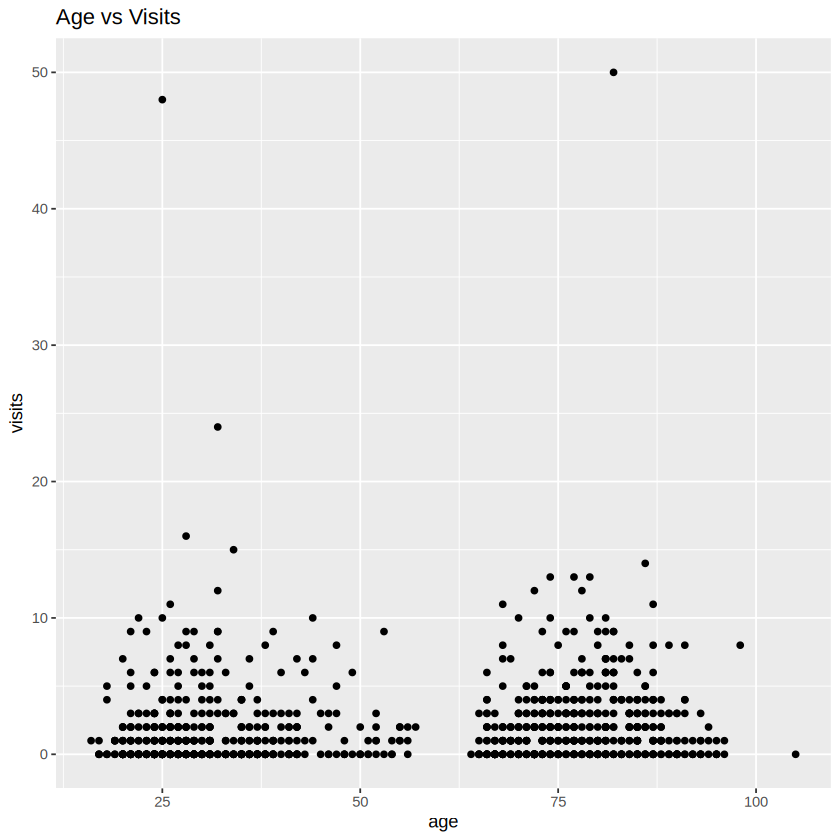

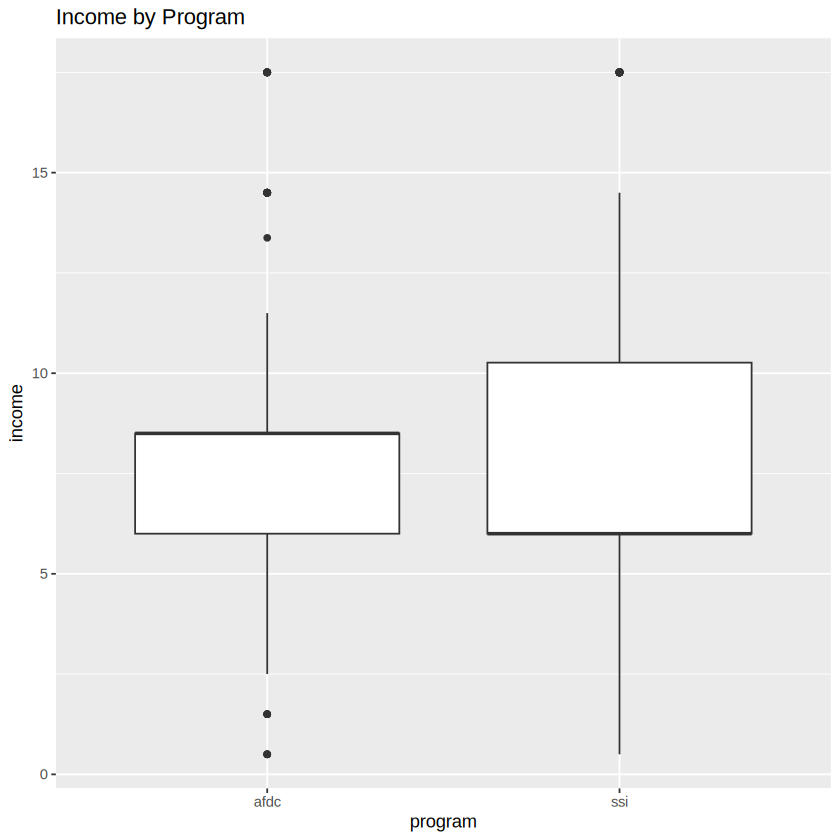

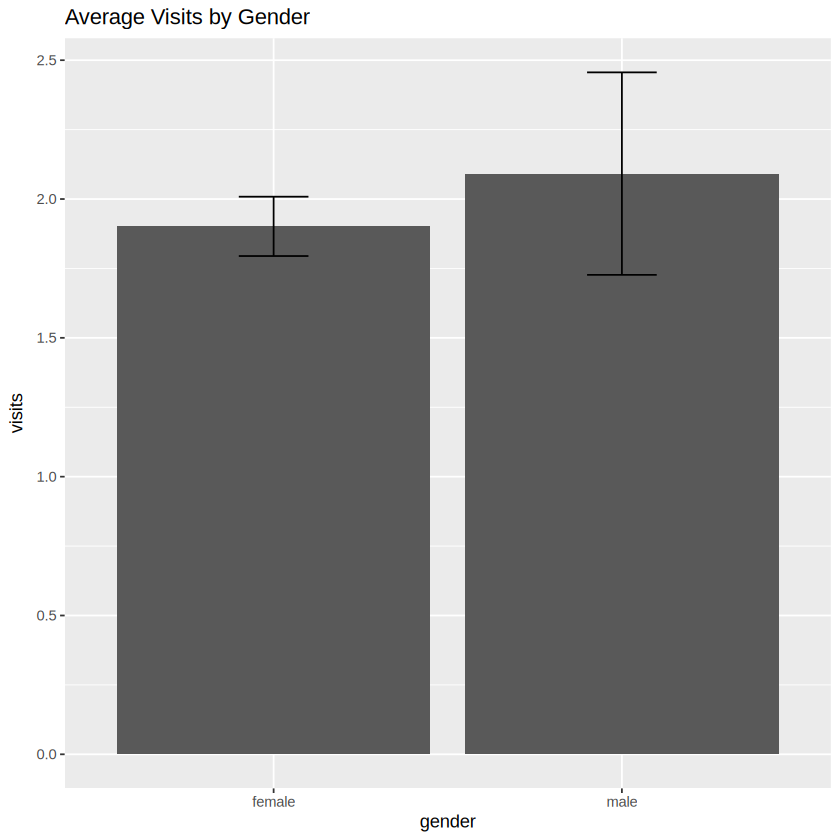

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


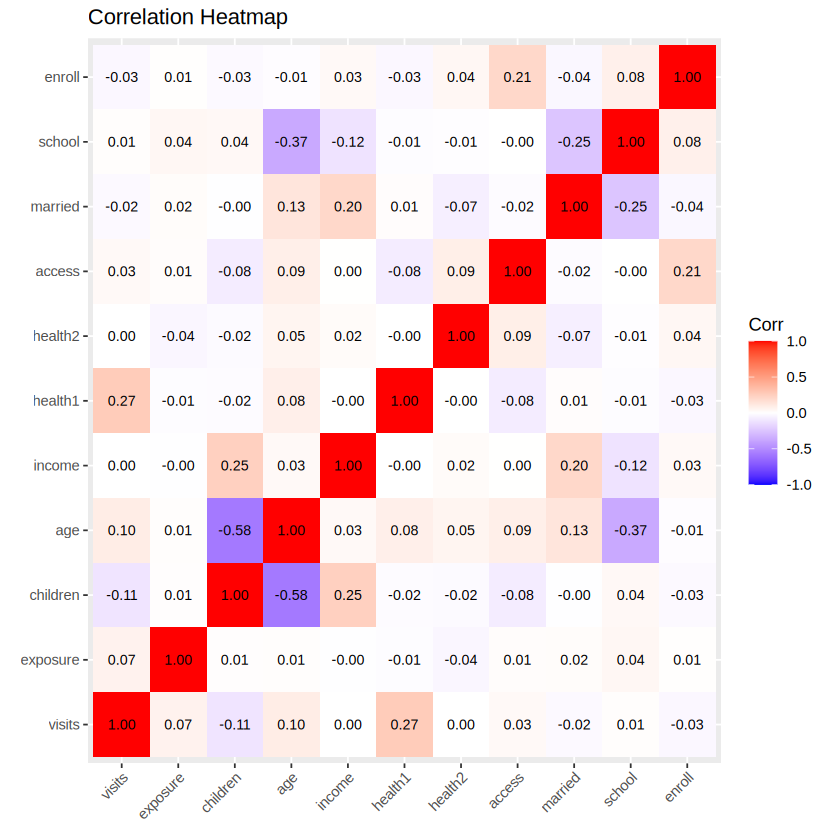

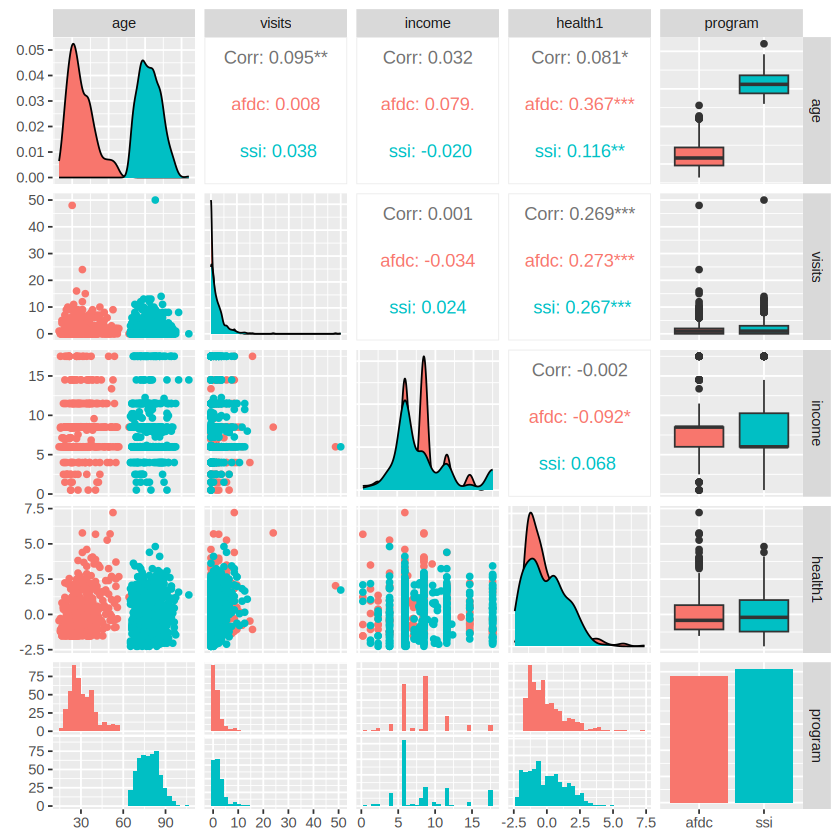

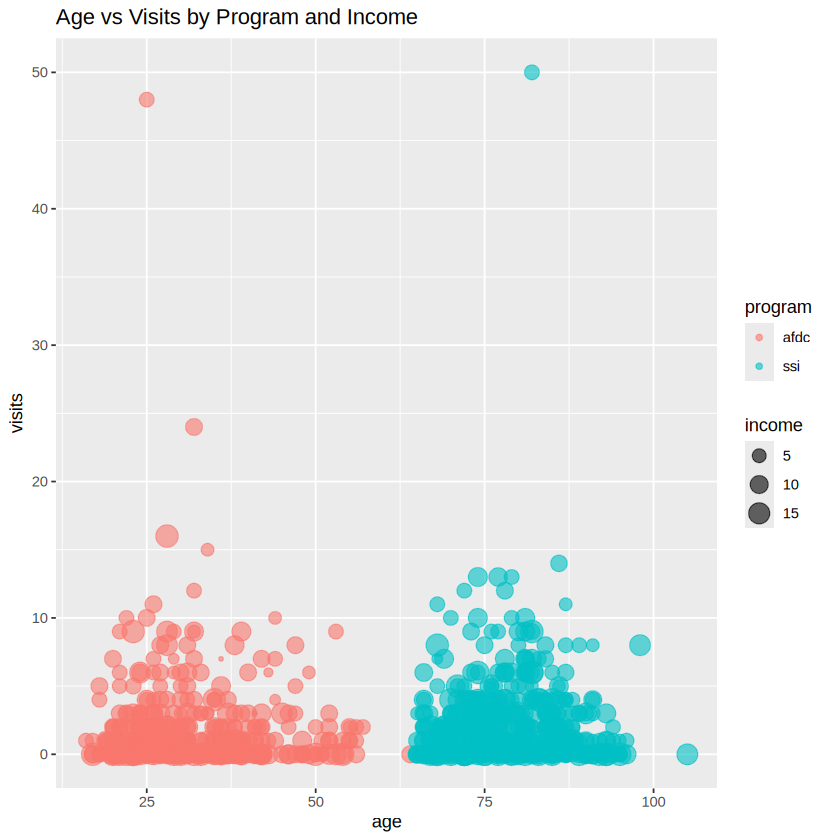

In [33]:
## Name: Pranath
# Reg No: 23BDS0241
# Topic: Exploratory Data Analysis (EDA) on the Medicaid1986 Dataset

# Install and load required packages
packages <- c("ggplot2", "dplyr", "GGally")
for (p in packages) {
  if (!requireNamespace(p, quietly = TRUE)) install.packages(p)
  library(p, character.only = TRUE)
}

#Basic statistical analysis
url <- "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Medicaid1986.csv"
df <- read.csv(url, stringsAsFactors = FALSE, na.strings = c("NA", ""))
head(df)
print(dim(df))
str(df)
print(summary(df))

#Handling missing data
print(colSums(is.na(df)))

num_cols <- names(df)[sapply(df, is.numeric)]
cat_cols <- names(df)[sapply(df, is.character)]

get_mode <- function(x) {
  ux <- unique(x[!is.na(x)])
  ux[which.max(tabulate(match(x, ux)))]
}

for (col in num_cols) {
  df[[col]][is.na(df[[col]])] <- median(df[[col]], na.rm = TRUE)
}
for (col in cat_cols) {
  df[[col]][is.na(df[[col]])] <- get_mode(df[[col]])
}

cat("Missing after handling:", sum(is.na(df)), "\n")

#Data cleaning
df <- distinct(df)

# the CSV's index column is read as "rownames" (or "X" if its header is blank)
df <- df[, !(names(df) %in% c("rownames", "X"))]

for (col in cat_cols) {
  df[[col]] <- tolower(trimws(df[[col]]))
}

q <- quantile(df$visits, c(0.25, 0.75))
Q1 <- q[[1]]
Q3 <- q[[2]]
IQR_val <- Q3 - Q1
outliers <- df[df$visits < Q1 - 1.5 * IQR_val | df$visits > Q3 + 1.5 * IQR_val, ]
cat("Outliers in visits:", nrow(outliers), "\n")

#Data transformation
for (col in c("married", "enroll")) {
  df[[col]] <- unname(c(yes = 1, no = 0)[df[[col]]])
}

# one-hot encoding with the first level dropped (drop_first = True)
dummies <- as.data.frame(model.matrix(~ gender + ethnicity + program, data = df)[, -1, drop = FALSE])
df_transformed <- cbind(df[, !(names(df) %in% c("gender", "ethnicity", "program"))], dummies)

df$age_group <- cut(df$age, breaks = c(0, 30, 50, 70, 120),
                    labels = c("<30", "30-50", "50-70", "70+"))

head(df)

#Bivariate analysis (3+ plots)
p1 <- ggplot(df, aes(x = age, y = visits)) +
  geom_point() +
  labs(title = "Age vs Visits")
print(p1)

p2 <- ggplot(df, aes(x = program, y = income)) +
  geom_boxplot() +
  labs(title = "Income by Program")
print(p2)

p3 <- ggplot(df, aes(x = gender, y = visits)) +
  stat_summary(fun = mean, geom = "bar") +
  stat_summary(fun.data = mean_se, geom = "errorbar", width = 0.2) +
  labs(title = "Average Visits by Gender")
print(p3)

#Multivariate analysis (3+ plots)
corr <- cor(df[sapply(df, is.numeric)], use = "complete.obs")
corr_long <- as.data.frame(as.table(corr))
p4 <- ggplot(corr_long, aes(x = Var1, y = Var2, fill = Freq)) +
  geom_tile() +
  geom_text(aes(label = sprintf("%.2f", Freq)), size = 3) +
  scale_fill_gradient2(low = "blue", mid = "white", high = "red",
                       midpoint = 0, limits = c(-1, 1)) +
  labs(title = "Correlation Heatmap", x = NULL, y = NULL, fill = "Corr") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))
print(p4)

p5 <- ggpairs(df[, c("age", "visits", "income", "health1", "program")],
              mapping = aes(color = program))
print(p5)

p6 <- ggplot(df, aes(x = age, y = visits, color = program, size = income)) +
  geom_point(alpha = 0.6) +
  labs(title = "Age vs Visits by Program and Income")
print(p6)

In [34]:
# Name: Pranath
# Reg No: 23BDS0241
# Topic: Exploratory Data Analysis (EDA) on the Medicaid1986 Dataset

#Load the dataset
library(ggplot2)
library(dplyr)

url <- "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Medicaid1986.csv"
df <- read.csv(url)
head(df)

,rownames,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,1,0,100,1,24,14.500,0.495,-0.854,0.50,no,female,cauc,13,yes,afdc
2,2,1,90,3,19,6.000,0.520,-0.969,0.17,no,female,cauc,11,yes,afdc
3,3,0,106,4,17,8.377,-1.227,0.317,0.42,no,female,cauc,12,yes,afdc
4,4,0,114,2,29,6.000,-1.524,0.457,0.33,no,female,cauc,12,yes,afdc
5,5,11,115,1,26,8.500,0.173,-0.599,0.67,no,female,cauc,16,yes,afdc
6,6,3,102,1,22,6.000,-0.905,0.062,0.25,no,female,other,12,yes,afdc


In [35]:
# Name: Pranath
# Reg No: 23BDS0241
# Topic: Exploratory Data Analysis (EDA) on the Medicaid1986 Dataset

library(ggplot2)
library(dplyr)

url <- "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Medicaid1986.csv"
df <- read.csv(url)
head(df)

#Basic statistical analysis
print(dim(df))
str(df)
print(summary(df))

,rownames,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,1,0,100,1,24,14.500,0.495,-0.854,0.50,no,female,cauc,13,yes,afdc
2,2,1,90,3,19,6.000,0.520,-0.969,0.17,no,female,cauc,11,yes,afdc
3,3,0,106,4,17,8.377,-1.227,0.317,0.42,no,female,cauc,12,yes,afdc
4,4,0,114,2,29,6.000,-1.524,0.457,0.33,no,female,cauc,12,yes,afdc
5,5,11,115,1,26,8.500,0.173,-0.599,0.67,no,female,cauc,16,yes,afdc
6,6,3,102,1,22,6.000,-0.905,0.062,0.25,no,female,other,12,yes,afdc


[1] 996  15
'data.frame':	996 obs. of  15 variables:
 $ rownames : int  1 2 3 4 5 6 7 8 9 10 ...
 $ visits   : int  0 1 0 0 11 3 0 6 1 0 ...
 $ exposure : int  100 90 106 114 115 102 92 92 117 101 ...
 $ children : int  1 3 4 2 1 1 2 1 1 1 ...
 $ age      : int  24 19 17 29 26 22 24 21 21 24 ...
 $ income   : num  14.5 6 8.38 6 8.5 ...
 $ health1  : num  0.495 0.52 -1.227 -1.524 0.173 ...
 $ health2  : num  -0.854 -0.969 0.317 0.457 -0.599 0.062 0.202 -0.981 0.317 -0.562 ...
 $ access   : num  0.5 0.17 0.42 0.33 0.67 0.25 0.5 0.67 0.25 0.67 ...
 $ married  : chr  "no" "no" "no" "no" ...
 $ gender   : chr  "female" "female" "female" "female" ...
 $ ethnicity: chr  "cauc" "cauc" "cauc" "cauc" ...
 $ school   : int  13 11 12 12 16 12 11 11 12 15 ...
 $ enroll   : chr  "yes" "yes" "yes" "yes" ...
 $ program  : chr  "afdc" "afdc" "afdc" "afdc" ...
    rownames         visits          exposure        children    
 Min.   :  1.0   Min.   : 0.000   Min.   : 32.0   Min.   :0.000  
 1st Qu.:249.

In [36]:
# Name: Pranath
# Reg No: 23BDS0241
# Topic: Exploratory Data Analysis (EDA) on the Medicaid1986 Dataset

library(ggplot2)
library(dplyr)

url <- "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Medicaid1986.csv"
df <- read.csv(url, stringsAsFactors = FALSE, na.strings = c("NA", ""))
head(df)
print(dim(df))
str(df)
print(summary(df))

#Handling missing data
print(colSums(is.na(df)))

num_cols <- names(df)[sapply(df, is.numeric)]
cat_cols <- names(df)[sapply(df, is.character)]

get_mode <- function(x) {
  ux <- unique(x[!is.na(x)])
  ux[which.max(tabulate(match(x, ux)))]
}

for (col in num_cols) {
  df[[col]][is.na(df[[col]])] <- median(df[[col]], na.rm = TRUE)
}
for (col in cat_cols) {
  df[[col]][is.na(df[[col]])] <- get_mode(df[[col]])
}

cat("Missing after handling:", sum(is.na(df)), "\n")


,rownames,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,1,0,100,1,24,14.500,0.495,-0.854,0.50,no,female,cauc,13,yes,afdc
2,2,1,90,3,19,6.000,0.520,-0.969,0.17,no,female,cauc,11,yes,afdc
3,3,0,106,4,17,8.377,-1.227,0.317,0.42,no,female,cauc,12,yes,afdc
4,4,0,114,2,29,6.000,-1.524,0.457,0.33,no,female,cauc,12,yes,afdc
5,5,11,115,1,26,8.500,0.173,-0.599,0.67,no,female,cauc,16,yes,afdc
6,6,3,102,1,22,6.000,-0.905,0.062,0.25,no,female,other,12,yes,afdc


[1] 996  15
'data.frame':	996 obs. of  15 variables:
 $ rownames : int  1 2 3 4 5 6 7 8 9 10 ...
 $ visits   : int  0 1 0 0 11 3 0 6 1 0 ...
 $ exposure : int  100 90 106 114 115 102 92 92 117 101 ...
 $ children : int  1 3 4 2 1 1 2 1 1 1 ...
 $ age      : int  24 19 17 29 26 22 24 21 21 24 ...
 $ income   : num  14.5 6 8.38 6 8.5 ...
 $ health1  : num  0.495 0.52 -1.227 -1.524 0.173 ...
 $ health2  : num  -0.854 -0.969 0.317 0.457 -0.599 0.062 0.202 -0.981 0.317 -0.562 ...
 $ access   : num  0.5 0.17 0.42 0.33 0.67 0.25 0.5 0.67 0.25 0.67 ...
 $ married  : chr  "no" "no" "no" "no" ...
 $ gender   : chr  "female" "female" "female" "female" ...
 $ ethnicity: chr  "cauc" "cauc" "cauc" "cauc" ...
 $ school   : int  13 11 12 12 16 12 11 11 12 15 ...
 $ enroll   : chr  "yes" "yes" "yes" "yes" ...
 $ program  : chr  "afdc" "afdc" "afdc" "afdc" ...
    rownames         visits          exposure        children    
 Min.   :  1.0   Min.   : 0.000   Min.   : 32.0   Min.   :0.000  
 1st Qu.:249.

In [37]:
# Name: Pranath
# Reg No: 23BDS0241
# Topic: Exploratory Data Analysis (EDA) on the Medicaid1986 Dataset

library(ggplot2)
library(dplyr)

url <- "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Medicaid1986.csv"
df <- read.csv(url, stringsAsFactors = FALSE, na.strings = c("NA", ""))
head(df)
print(dim(df))
str(df)
print(summary(df))

#Handling missing data
print(colSums(is.na(df)))

num_cols <- names(df)[sapply(df, is.numeric)]
cat_cols <- names(df)[sapply(df, is.character)]

get_mode <- function(x) {
  ux <- unique(x[!is.na(x)])
  ux[which.max(tabulate(match(x, ux)))]
}

for (col in num_cols) {
  df[[col]][is.na(df[[col]])] <- median(df[[col]], na.rm = TRUE)
}
for (col in cat_cols) {
  df[[col]][is.na(df[[col]])] <- get_mode(df[[col]])
}

cat("Missing after handling:", sum(is.na(df)), "\n")

#Data cleaning
df <- distinct(df)

# the CSV's index column is

,rownames,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,1,0,100,1,24,14.500,0.495,-0.854,0.50,no,female,cauc,13,yes,afdc
2,2,1,90,3,19,6.000,0.520,-0.969,0.17,no,female,cauc,11,yes,afdc
3,3,0,106,4,17,8.377,-1.227,0.317,0.42,no,female,cauc,12,yes,afdc
4,4,0,114,2,29,6.000,-1.524,0.457,0.33,no,female,cauc,12,yes,afdc
5,5,11,115,1,26,8.500,0.173,-0.599,0.67,no,female,cauc,16,yes,afdc
6,6,3,102,1,22,6.000,-0.905,0.062,0.25,no,female,other,12,yes,afdc


[1] 996  15
'data.frame':	996 obs. of  15 variables:
 $ rownames : int  1 2 3 4 5 6 7 8 9 10 ...
 $ visits   : int  0 1 0 0 11 3 0 6 1 0 ...
 $ exposure : int  100 90 106 114 115 102 92 92 117 101 ...
 $ children : int  1 3 4 2 1 1 2 1 1 1 ...
 $ age      : int  24 19 17 29 26 22 24 21 21 24 ...
 $ income   : num  14.5 6 8.38 6 8.5 ...
 $ health1  : num  0.495 0.52 -1.227 -1.524 0.173 ...
 $ health2  : num  -0.854 -0.969 0.317 0.457 -0.599 0.062 0.202 -0.981 0.317 -0.562 ...
 $ access   : num  0.5 0.17 0.42 0.33 0.67 0.25 0.5 0.67 0.25 0.67 ...
 $ married  : chr  "no" "no" "no" "no" ...
 $ gender   : chr  "female" "female" "female" "female" ...
 $ ethnicity: chr  "cauc" "cauc" "cauc" "cauc" ...
 $ school   : int  13 11 12 12 16 12 11 11 12 15 ...
 $ enroll   : chr  "yes" "yes" "yes" "yes" ...
 $ program  : chr  "afdc" "afdc" "afdc" "afdc" ...
    rownames         visits          exposure        children    
 Min.   :  1.0   Min.   : 0.000   Min.   : 32.0   Min.   :0.000  
 1st Qu.:249.

In [38]:
# Name: Pranath
# Reg No: 23BDS0241
# Topic: Exploratory Data Analysis (EDA) on the Medicaid1986 Dataset

library(ggplot2)
library(dplyr)

url <- "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Medicaid1986.csv"
df <- read.csv(url, stringsAsFactors = FALSE, na.strings = c("NA", ""))
head(df)
print(dim(df))
str(df)
print(summary(df))
print(colSums(is.na(df)))

num_cols <- names(df)[sapply(df, is.numeric)]
cat_cols <- names(df)[sapply(df, is.character)]

get_mode <- function(x) {
  ux <- unique(x[!is.na(x)])
  ux[which.max(tabulate(match(x, ux)))]
}

for (col in num_cols) {
  df[[col]][is.na(df[[col]])] <- median(df[[col]], na.rm = TRUE)
}
for (col in cat_cols) {
  df[[col]][is.na(df[[col]])] <- get_mode(df[[col]])
}

cat("Missing after handling:", sum(is.na(df)), "\n")

df <- distinct(df)

# the CSV's index column is read as "rownames" (or "X" if its header is blank)
df <- df[, !(names(df) %in% c("rownames", "X"))]

for (col in cat_cols) {
  df[[col]] <- tolower(trimws(df[[col]]))
}

q <- quantile(df$visits, c(0.25, 0.75))
Q1 <- q[[1]]
Q3 <- q[[2]]
IQR_val <- Q3 - Q1
outliers <- df[df$visits < Q1 - 1.5 * IQR_val | df$visits > Q3 + 1.5 * IQR_val, ]
cat("Outliers in visits:", nrow(outliers), "\n")

#Data transformation
for (col in c("married", "enroll")) {
  df[[col]] <- unname(c(yes = 1, no = 0)[df[[col]]])
}

# one-hot encoding with the first level dropped (drop_first = True)
dummies <- as.data.frame(model.matrix(~ gender + ethnicity + program, data = df)[, -1, drop = FALSE])
df_transformed <- cbind(df[, !(names(df) %in% c("gender", "ethnicity", "program"))], dummies)

df$age_group <- cut(df$age, breaks = c(0, 30, 50, 70, 120),
                    labels = c("<30", "30-50", "50-70", "70+"))

head(df)

,rownames,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,1,0,100,1,24,14.500,0.495,-0.854,0.50,no,female,cauc,13,yes,afdc
2,2,1,90,3,19,6.000,0.520,-0.969,0.17,no,female,cauc,11,yes,afdc
3,3,0,106,4,17,8.377,-1.227,0.317,0.42,no,female,cauc,12,yes,afdc
4,4,0,114,2,29,6.000,-1.524,0.457,0.33,no,female,cauc,12,yes,afdc
5,5,11,115,1,26,8.500,0.173,-0.599,0.67,no,female,cauc,16,yes,afdc
6,6,3,102,1,22,6.000,-0.905,0.062,0.25,no,female,other,12,yes,afdc


[1] 996  15
'data.frame':	996 obs. of  15 variables:
 $ rownames : int  1 2 3 4 5 6 7 8 9 10 ...
 $ visits   : int  0 1 0 0 11 3 0 6 1 0 ...
 $ exposure : int  100 90 106 114 115 102 92 92 117 101 ...
 $ children : int  1 3 4 2 1 1 2 1 1 1 ...
 $ age      : int  24 19 17 29 26 22 24 21 21 24 ...
 $ income   : num  14.5 6 8.38 6 8.5 ...
 $ health1  : num  0.495 0.52 -1.227 -1.524 0.173 ...
 $ health2  : num  -0.854 -0.969 0.317 0.457 -0.599 0.062 0.202 -0.981 0.317 -0.562 ...
 $ access   : num  0.5 0.17 0.42 0.33 0.67 0.25 0.5 0.67 0.25 0.67 ...
 $ married  : chr  "no" "no" "no" "no" ...
 $ gender   : chr  "female" "female" "female" "female" ...
 $ ethnicity: chr  "cauc" "cauc" "cauc" "cauc" ...
 $ school   : int  13 11 12 12 16 12 11 11 12 15 ...
 $ enroll   : chr  "yes" "yes" "yes" "yes" ...
 $ program  : chr  "afdc" "afdc" "afdc" "afdc" ...
    rownames         visits          exposure        children    
 Min.   :  1.0   Min.   : 0.000   Min.   : 32.0   Min.   :0.000  
 1st Qu.:249.

,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program,age_group
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<fct>
1,0,100,1,24,14.500,0.495,-0.854,0.50,0,female,cauc,13,1,afdc,<30
2,1,90,3,19,6.000,0.520,-0.969,0.17,0,female,cauc,11,1,afdc,<30
3,0,106,4,17,8.377,-1.227,0.317,0.42,0,female,cauc,12,1,afdc,<30
4,0,114,2,29,6.000,-1.524,0.457,0.33,0,female,cauc,12,1,afdc,<30
5,11,115,1,26,8.500,0.173,-0.599,0.67,0,female,cauc,16,1,afdc,<30
6,3,102,1,22,6.000,-0.905,0.062,0.25,0,female,other,12,1,afdc,<30


,rownames,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,1,0,100,1,24,14.500,0.495,-0.854,0.50,no,female,cauc,13,yes,afdc
2,2,1,90,3,19,6.000,0.520,-0.969,0.17,no,female,cauc,11,yes,afdc
3,3,0,106,4,17,8.377,-1.227,0.317,0.42,no,female,cauc,12,yes,afdc
4,4,0,114,2,29,6.000,-1.524,0.457,0.33,no,female,cauc,12,yes,afdc
5,5,11,115,1,26,8.500,0.173,-0.599,0.67,no,female,cauc,16,yes,afdc
6,6,3,102,1,22,6.000,-0.905,0.062,0.25,no,female,other,12,yes,afdc


[1] 996  15
'data.frame':	996 obs. of  15 variables:
 $ rownames : int  1 2 3 4 5 6 7 8 9 10 ...
 $ visits   : int  0 1 0 0 11 3 0 6 1 0 ...
 $ exposure : int  100 90 106 114 115 102 92 92 117 101 ...
 $ children : int  1 3 4 2 1 1 2 1 1 1 ...
 $ age      : int  24 19 17 29 26 22 24 21 21 24 ...
 $ income   : num  14.5 6 8.38 6 8.5 ...
 $ health1  : num  0.495 0.52 -1.227 -1.524 0.173 ...
 $ health2  : num  -0.854 -0.969 0.317 0.457 -0.599 0.062 0.202 -0.981 0.317 -0.562 ...
 $ access   : num  0.5 0.17 0.42 0.33 0.67 0.25 0.5 0.67 0.25 0.67 ...
 $ married  : chr  "no" "no" "no" "no" ...
 $ gender   : chr  "female" "female" "female" "female" ...
 $ ethnicity: chr  "cauc" "cauc" "cauc" "cauc" ...
 $ school   : int  13 11 12 12 16 12 11 11 12 15 ...
 $ enroll   : chr  "yes" "yes" "yes" "yes" ...
 $ program  : chr  "afdc" "afdc" "afdc" "afdc" ...
    rownames         visits          exposure        children    
 Min.   :  1.0   Min.   : 0.000   Min.   : 32.0   Min.   :0.000  
 1st Qu.:249.

,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program,age_group
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<fct>
1,0,100,1,24,14.500,0.495,-0.854,0.50,0,female,cauc,13,1,afdc,<30
2,1,90,3,19,6.000,0.520,-0.969,0.17,0,female,cauc,11,1,afdc,<30
3,0,106,4,17,8.377,-1.227,0.317,0.42,0,female,cauc,12,1,afdc,<30
4,0,114,2,29,6.000,-1.524,0.457,0.33,0,female,cauc,12,1,afdc,<30
5,11,115,1,26,8.500,0.173,-0.599,0.67,0,female,cauc,16,1,afdc,<30
6,3,102,1,22,6.000,-0.905,0.062,0.25,0,female,other,12,1,afdc,<30


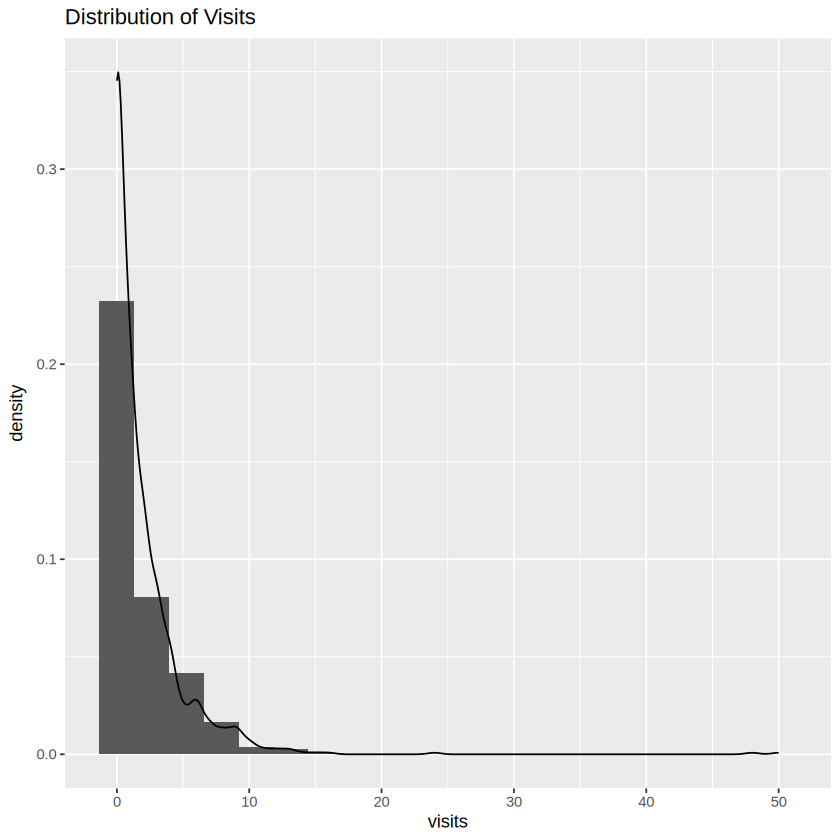

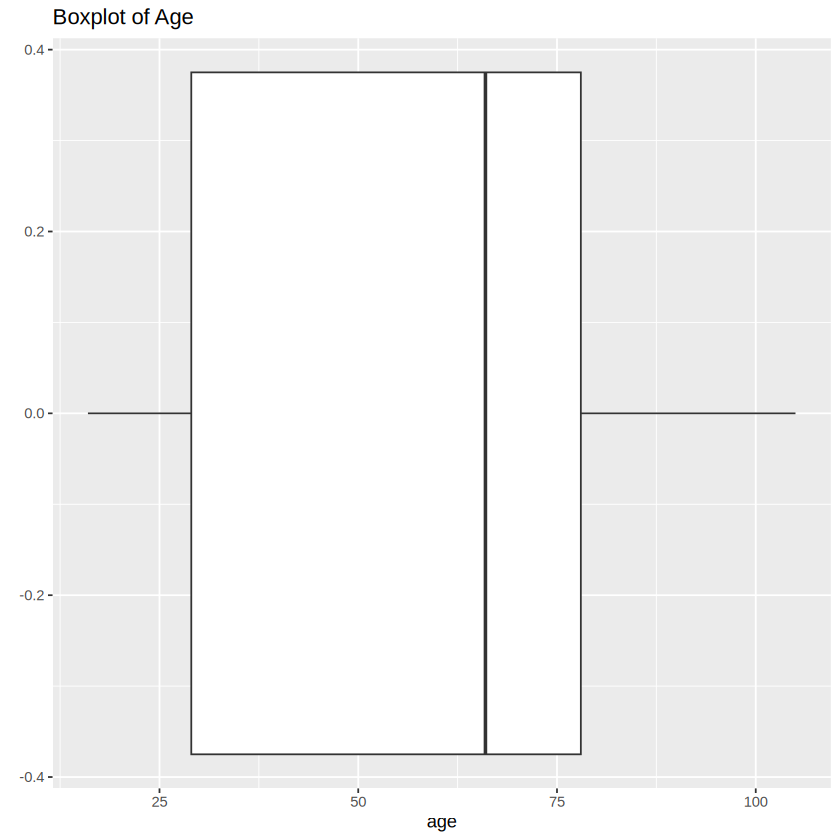

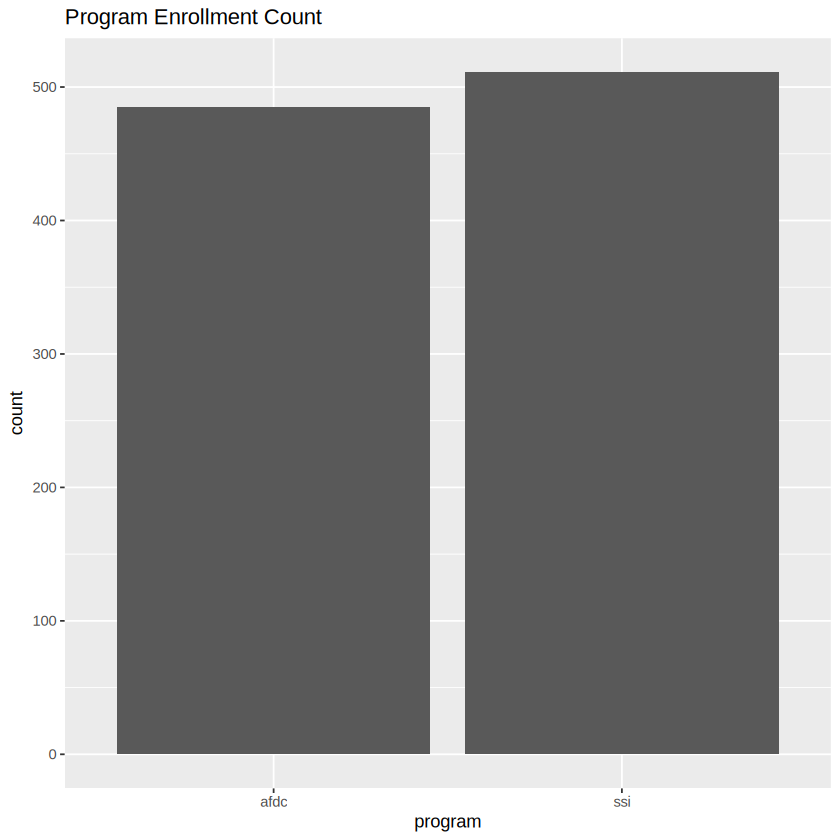

In [39]:
# Name: Pranath
# Reg No: 23BDS0241
# Topic: Exploratory Data Analysis (EDA) on the Medicaid1986 Dataset

library(ggplot2)
library(dplyr)

url <- "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Medicaid1986.csv"
df <- read.csv(url, stringsAsFactors = FALSE, na.strings = c("NA", ""))
head(df)
print(dim(df))
str(df)
print(summary(df))
print(colSums(is.na(df)))

# Fill numeric columns with median, categorical with mode (safe even if 0 missing)
num_cols <- names(df)[sapply(df, is.numeric)]
cat_cols <- names(df)[sapply(df, is.character)]

get_mode <- function(x) {
  ux <- unique(x[!is.na(x)])
  ux[which.max(tabulate(match(x, ux)))]
}

for (col in num_cols) {
  df[[col]][is.na(df[[col]])] <- median(df[[col]], na.rm = TRUE)
}
for (col in cat_cols) {
  df[[col]][is.na(df[[col]])] <- get_mode(df[[col]])
}

cat("Missing after handling:", sum(is.na(df)), "\n")

# Drop duplicates
df <- distinct(df)

# Drop the row index column (not useful for analysis)
drop_cols <- c("rownames", "X")
df <- df[, !(names(df) %in% drop_cols)]

# Strip whitespace from categorical text
for (col in cat_cols) {
  df[[col]] <- tolower(trimws(df[[col]]))
}

# Check for outliers using IQR on visits
q <- quantile(df$visits, c(0.25, 0.75))
Q1 <- q[[1]]
Q3 <- q[[2]]
IQR_val <- Q3 - Q1
low <- Q1 - 1.5 * IQR_val
high <- Q3 + 1.5 * IQR_val
outliers <- df[df$visits < low | df$visits > high, ]
cat("Outliers in visits:", nrow(outliers), "\n")

# Binary encode yes/no columns
for (col in c("married", "enroll")) {
  df[[col]] <- unname(c(yes = 1, no = 0)[df[[col]]])
}

# One-hot encode gender, ethnicity, program (first level dropped)
dummies <- model.matrix(~ gender + ethnicity + program, data = df)
dummies <- as.data.frame(dummies[, -1, drop = FALSE])
keep <- setdiff(names(df), c("gender", "ethnicity", "program"))
df_transformed <- cbind(df[, keep], dummies)

# Feature engineering: age groups
brks <- c(0, 30, 50, 70, 120)
labs <- c("<30", "30-50", "50-70", "70+")
df$age_group <- cut(df$age, breaks = brks, labels = labs)

head(df)

#Univariate analysis (3+ plots)
p1 <- ggplot(df, aes(x = visits)) +
  geom_histogram(aes(y = after_stat(density)), bins = 20) +
  geom_density() +
  labs(title = "Distribution of Visits")
print(p1)

p2 <- ggplot(df, aes(x = age)) +
  geom_boxplot() +
  labs(title = "Boxplot of Age")
print(p2)

p3 <- ggplot(df, aes(x = program)) +
  geom_bar() +
  labs(title = "Program Enrollment Count")
print(p3)

,rownames,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,1,0,100,1,24,14.500,0.495,-0.854,0.50,no,female,cauc,13,yes,afdc
2,2,1,90,3,19,6.000,0.520,-0.969,0.17,no,female,cauc,11,yes,afdc
3,3,0,106,4,17,8.377,-1.227,0.317,0.42,no,female,cauc,12,yes,afdc
4,4,0,114,2,29,6.000,-1.524,0.457,0.33,no,female,cauc,12,yes,afdc
5,5,11,115,1,26,8.500,0.173,-0.599,0.67,no,female,cauc,16,yes,afdc
6,6,3,102,1,22,6.000,-0.905,0.062,0.25,no,female,other,12,yes,afdc


[1] 996  15
'data.frame':	996 obs. of  15 variables:
 $ rownames : int  1 2 3 4 5 6 7 8 9 10 ...
 $ visits   : int  0 1 0 0 11 3 0 6 1 0 ...
 $ exposure : int  100 90 106 114 115 102 92 92 117 101 ...
 $ children : int  1 3 4 2 1 1 2 1 1 1 ...
 $ age      : int  24 19 17 29 26 22 24 21 21 24 ...
 $ income   : num  14.5 6 8.38 6 8.5 ...
 $ health1  : num  0.495 0.52 -1.227 -1.524 0.173 ...
 $ health2  : num  -0.854 -0.969 0.317 0.457 -0.599 0.062 0.202 -0.981 0.317 -0.562 ...
 $ access   : num  0.5 0.17 0.42 0.33 0.67 0.25 0.5 0.67 0.25 0.67 ...
 $ married  : chr  "no" "no" "no" "no" ...
 $ gender   : chr  "female" "female" "female" "female" ...
 $ ethnicity: chr  "cauc" "cauc" "cauc" "cauc" ...
 $ school   : int  13 11 12 12 16 12 11 11 12 15 ...
 $ enroll   : chr  "yes" "yes" "yes" "yes" ...
 $ program  : chr  "afdc" "afdc" "afdc" "afdc" ...
    rownames         visits          exposure        children    
 Min.   :  1.0   Min.   : 0.000   Min.   : 32.0   Min.   :0.000  
 1st Qu.:249.

,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program,age_group
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<fct>
1,0,100,1,24,14.500,0.495,-0.854,0.50,0,female,cauc,13,1,afdc,<30
2,1,90,3,19,6.000,0.520,-0.969,0.17,0,female,cauc,11,1,afdc,<30
3,0,106,4,17,8.377,-1.227,0.317,0.42,0,female,cauc,12,1,afdc,<30
4,0,114,2,29,6.000,-1.524,0.457,0.33,0,female,cauc,12,1,afdc,<30
5,11,115,1,26,8.500,0.173,-0.599,0.67,0,female,cauc,16,1,afdc,<30
6,3,102,1,22,6.000,-0.905,0.062,0.25,0,female,other,12,1,afdc,<30


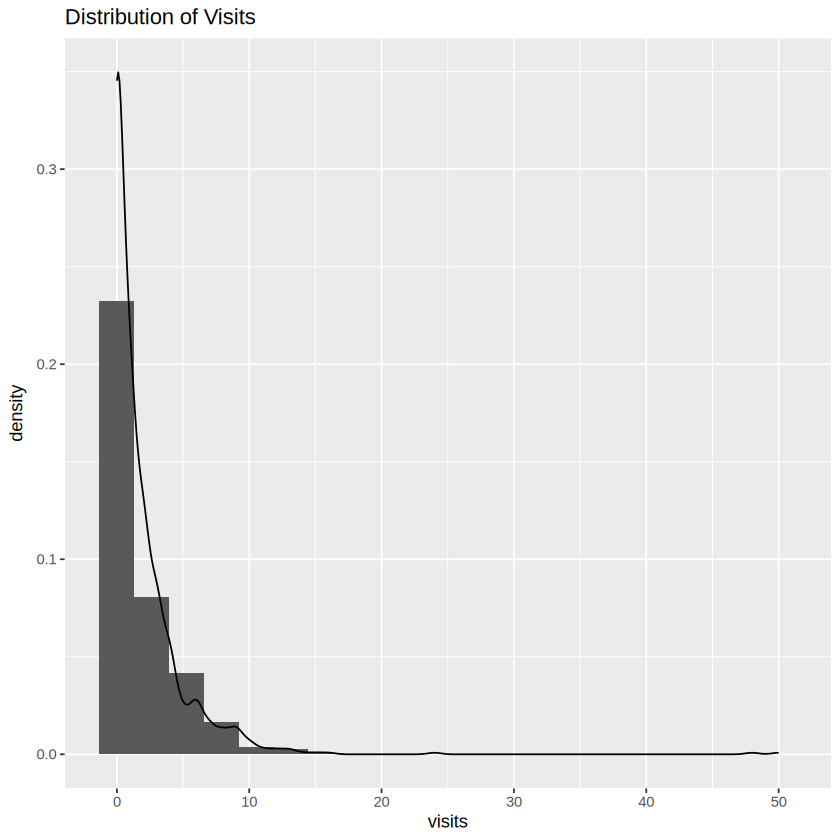

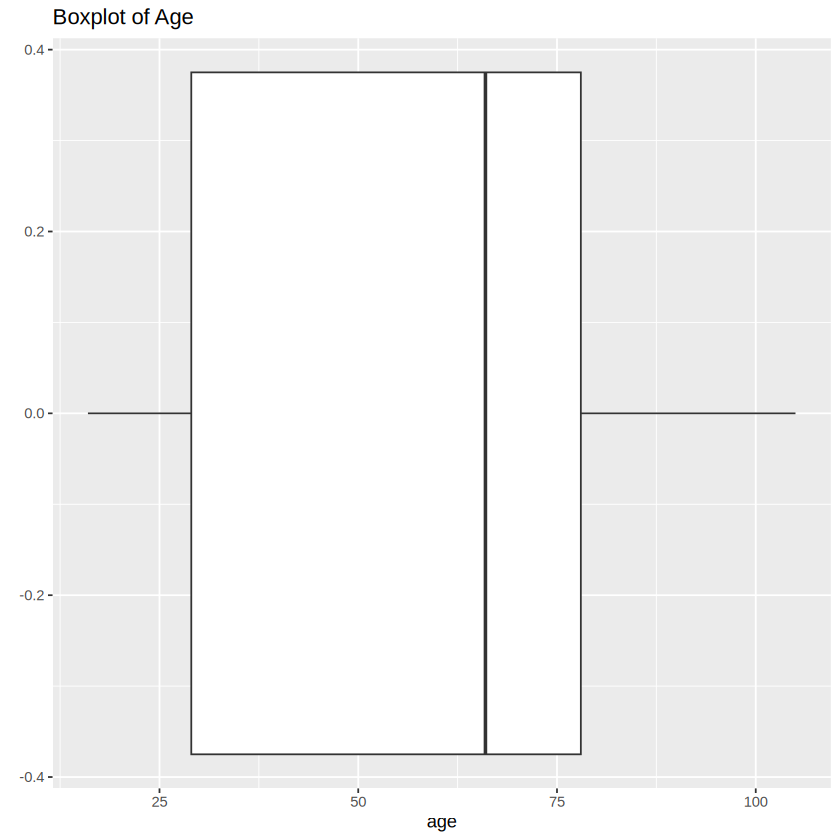

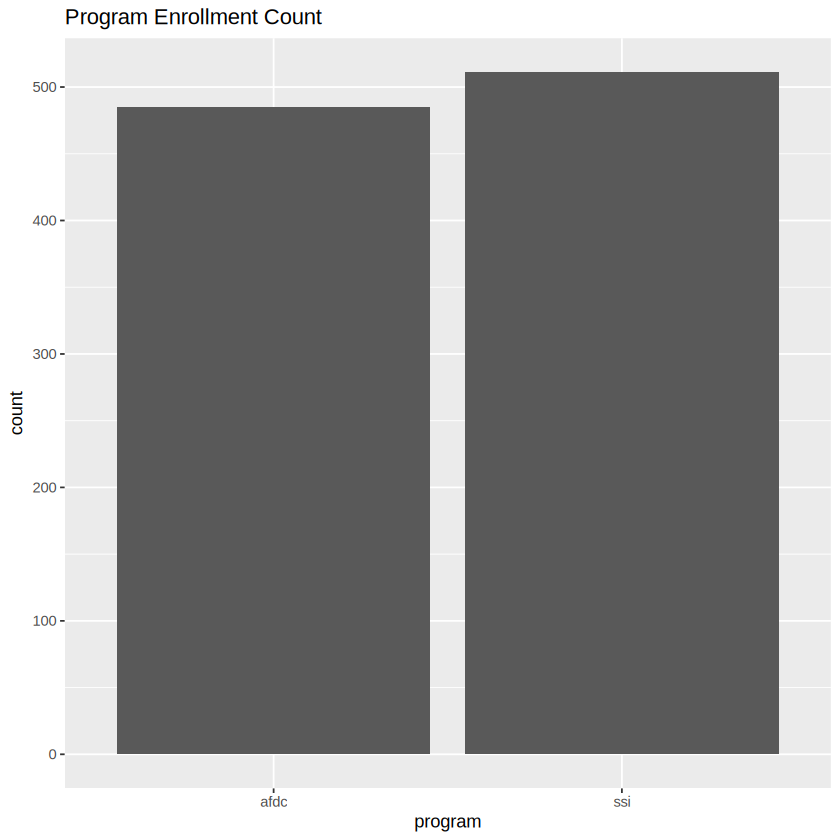

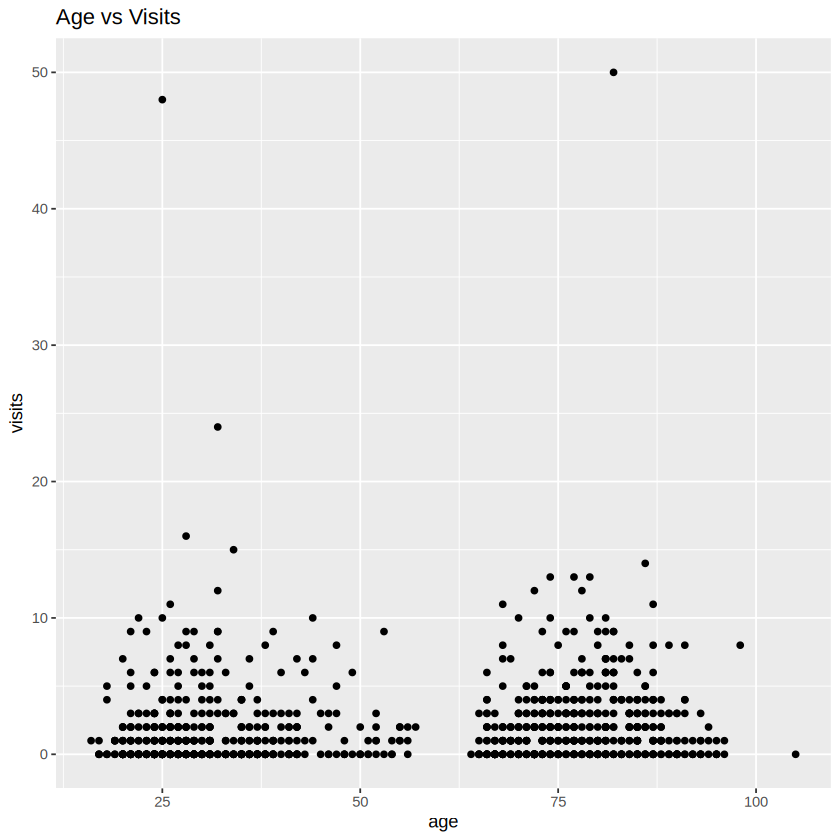

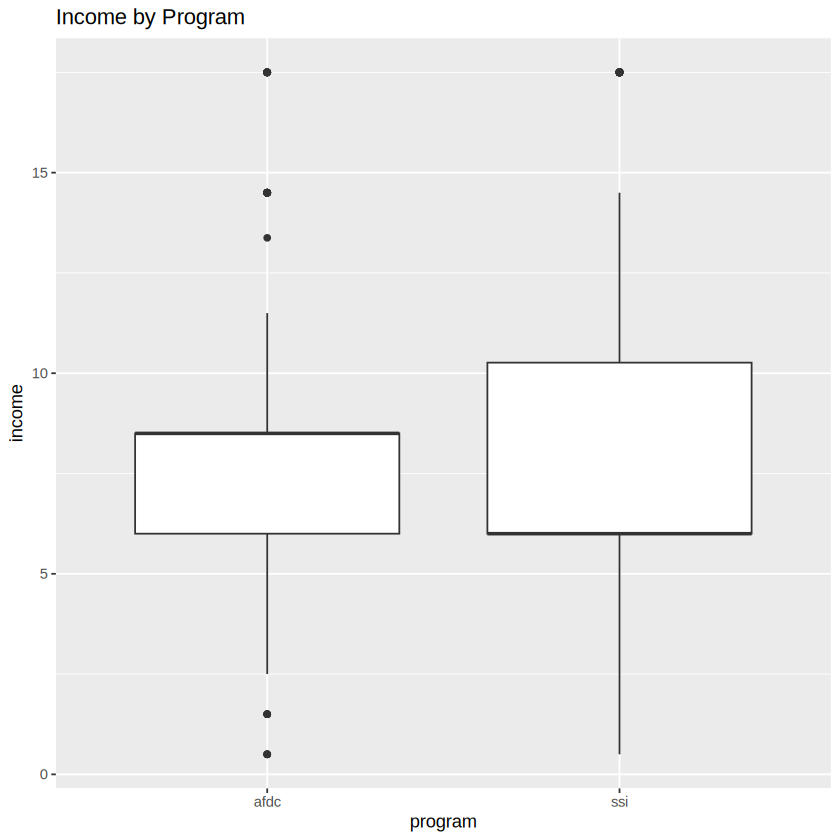

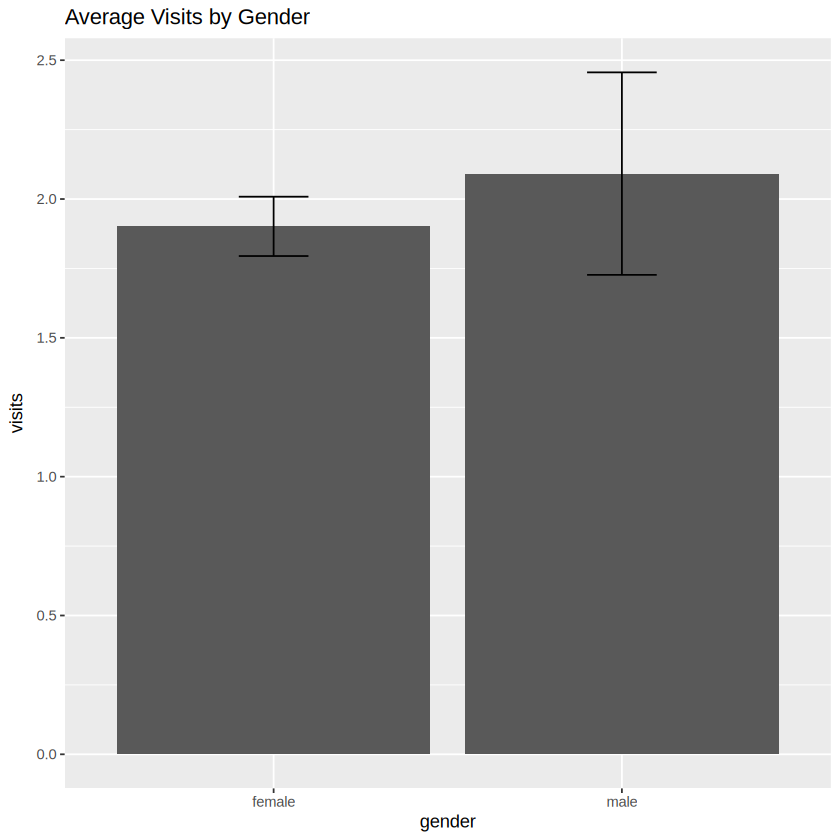

In [40]:
# Name: Pranath
# Reg No: 23BDS0241
# Topic: Exploratory Data Analysis (EDA) on the Medicaid1986 Dataset

library(ggplot2)
library(dplyr)

url <- "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Medicaid1986.csv"
df <- read.csv(url, stringsAsFactors = FALSE, na.strings = c("NA", ""))
head(df)
print(dim(df))
str(df)
print(summary(df))
print(colSums(is.na(df)))

num_cols <- names(df)[sapply(df, is.numeric)]
cat_cols <- names(df)[sapply(df, is.character)]

get_mode <- function(x) {
  ux <- unique(x[!is.na(x)])
  ux[which.max(tabulate(match(x, ux)))]
}

for (col in num_cols) {
  df[[col]][is.na(df[[col]])] <- median(df[[col]], na.rm = TRUE)
}
for (col in cat_cols) {
  df[[col]][is.na(df[[col]])] <- get_mode(df[[col]])
}

cat("Missing after handling:", sum(is.na(df)), "\n")

df <- distinct(df)

drop_cols <- c("rownames", "X")
df <- df[, !(names(df) %in% drop_cols)]

for (col in cat_cols) {
  df[[col]] <- tolower(trimws(df[[col]]))
}

q <- quantile(df$visits, c(0.25, 0.75))
Q1 <- q[[1]]
Q3 <- q[[2]]
IQR_val <- Q3 - Q1
low <- Q1 - 1.5 * IQR_val
high <- Q3 + 1.5 * IQR_val
outliers <- df[df$visits < low | df$visits > high, ]
cat("Outliers in visits:", nrow(outliers), "\n")

for (col in c("married", "enroll")) {
  df[[col]] <- unname(c(yes = 1, no = 0)[df[[col]]])
}

dummies <- model.matrix(~ gender + ethnicity + program, data = df)
dummies <- as.data.frame(dummies[, -1, drop = FALSE])
keep <- setdiff(names(df), c("gender", "ethnicity", "program"))
df_transformed <- cbind(df[, keep], dummies)

brks <- c(0, 30, 50, 70, 120)
labs <- c("<30", "30-50", "50-70", "70+")
df$age_group <- cut(df$age, breaks = brks, labels = labs)

head(df)

#Univariate analysis (3+ plots)
p1 <- ggplot(df, aes(x = visits)) +
  geom_histogram(aes(y = after_stat(density)), bins = 20) +
  geom_density() +
  labs(title = "Distribution of Visits")
print(p1)

p2 <- ggplot(df, aes(x = age)) +
  geom_boxplot() +
  labs(title = "Boxplot of Age")
print(p2)

p3 <- ggplot(df, aes(x = program)) +
  geom_bar() +
  labs(title = "Program Enrollment Count")
print(p3)

#Bivariate analysis (3+ plots)
p4 <- ggplot(df, aes(x = age, y = visits)) +
  geom_point() +
  labs(title = "Age vs Visits")
print(p4)

p5 <- ggplot(df, aes(x = program, y = income)) +
  geom_boxplot() +
  labs(title = "Income by Program")
print(p5)

p6 <- ggplot(df, aes(x = gender, y = visits)) +
  stat_summary(fun = mean, geom = "bar") +
  stat_summary(fun.data = mean_se, geom = "errorbar", width = 0.2) +
  labs(title = "Average Visits by Gender")
print(p6)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



,rownames,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,1,0,100,1,24,14.500,0.495,-0.854,0.50,no,female,cauc,13,yes,afdc
2,2,1,90,3,19,6.000,0.520,-0.969,0.17,no,female,cauc,11,yes,afdc
3,3,0,106,4,17,8.377,-1.227,0.317,0.42,no,female,cauc,12,yes,afdc
4,4,0,114,2,29,6.000,-1.524,0.457,0.33,no,female,cauc,12,yes,afdc
5,5,11,115,1,26,8.500,0.173,-0.599,0.67,no,female,cauc,16,yes,afdc
6,6,3,102,1,22,6.000,-0.905,0.062,0.25,no,female,other,12,yes,afdc



---------- visits ----------
Mean     : 1.931 
Median   : 1 
Mode     : 0 
Variance : 11.252 
Std.Dev  : 3.354 
Range    : 0 to 50 
IQR      : 3 
Skewness : 6.656 
Kurtosis : 82.466 

---------- exposure ----------
Mean     : 104.06 
Median   : 104 
Mode     : 106 
Variance : 83.631 
Std.Dev  : 9.145 
Range    : 32 to 120 
IQR      : 13 
Skewness : -1.057 
Kurtosis : 9.282 

---------- children ----------
Mean     : 1.314 
Median   : 1 
Mode     : 0 
Variance : 2.278 
Std.Dev  : 1.509 
Range    : 0 to 9 
IQR      : 2 
Skewness : 1.181 
Kurtosis : 4.219 

---------- age ----------
Mean     : 55.206 
Median   : 66 
Mode     : 24 
Variance : 623.07 
Std.Dev  : 24.961 
Range    : 16 to 105 
IQR      : 49 
Skewness : -0.069 
Kurtosis : 1.359 

---------- income ----------
Mean     : 8.191 
Median   : 7.99 
Mode     : 6 
Variance : 13.181 
Std.Dev  : 3.631 
Range    : 0.5 to 17.5 
IQR      : 2.5 
Skewness : 1.044 
Kurtosis : 3.954 

---------- health1 ----------
Mean     : 0 
Median   : -0.

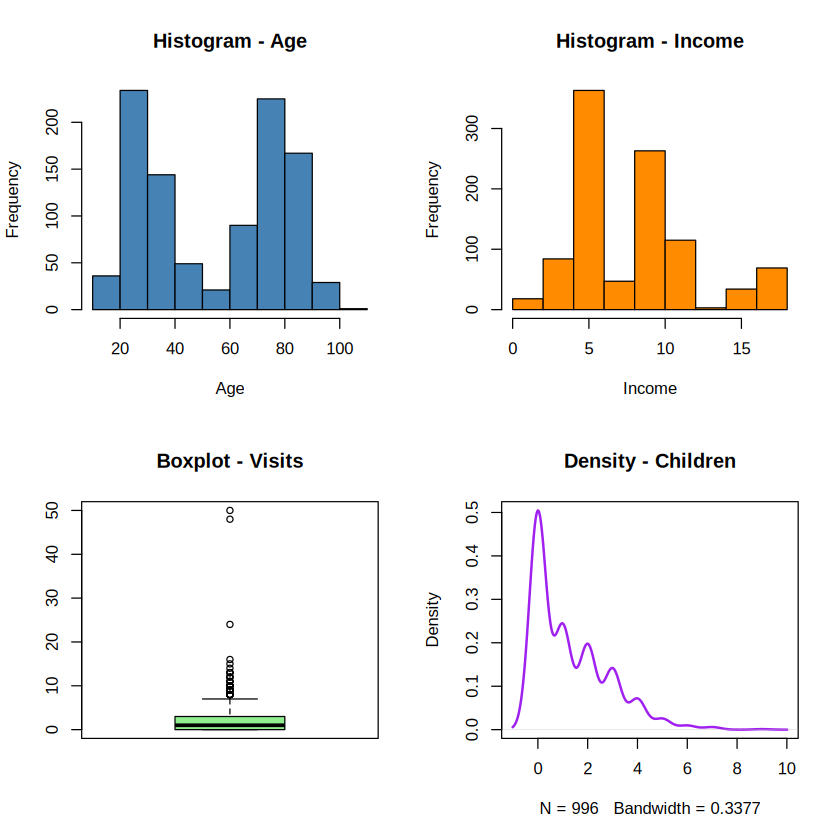

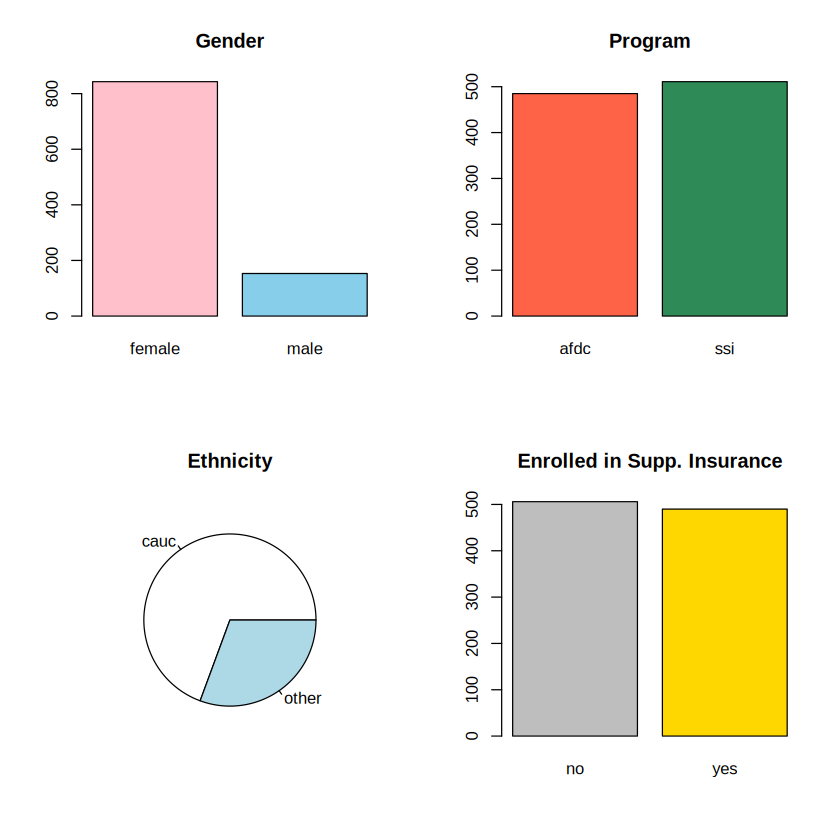

In [41]:
# Name   : Pranath
# Reg No : 23BDS0241
# Title  : 1-D (Univariate) Statistical Analysis on Medicaid1986 Dataset

install.packages("moments")   # run once if not installed

data <- read.csv("https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Medicaid1986.csv")
head(data)

data$married   <- factor(data$married)
data$gender    <- factor(data$gender)
data$ethnicity <- factor(data$ethnicity)
data$enroll    <- factor(data$enroll)
data$program   <- factor(data$program)

numeric_cols <- c("visits","exposure","children","age","income","health1","health2","access","school")
factor_cols  <- c("married","gender","ethnicity","enroll","program")

get_mode <- function(v) {
  uv <- unique(v)
  uv[which.max(tabulate(match(v, uv)))]
}

for (v in numeric_cols) {
  cat("\n----------", v, "----------\n")
  cat("Mean     :", round(mean(data[[v]]), 3), "\n")
  cat("Median   :", round(median(data[[v]]), 3), "\n")
  cat("Mode     :", round(get_mode(data[[v]]), 3), "\n")
  cat("Variance :", round(var(data[[v]]), 3), "\n")
  cat("Std.Dev  :", round(sd(data[[v]]), 3), "\n")
  cat("Range    :", paste(range(data[[v]]), collapse = " to "), "\n")
  cat("IQR      :", round(IQR(data[[v]]), 3), "\n")
  cat("Skewness :", round(moments::skewness(data[[v]]), 3), "\n")
  cat("Kurtosis :", round(moments::kurtosis(data[[v]]), 3), "\n")
}

for (f in factor_cols) {
  cat("\nFrequency table -", f, "\n")
  print(table(data[[f]]))
  print(round(prop.table(table(data[[f]])) * 100, 1))
}

par(mfrow = c(2, 2))
hist(data$age, main = "Histogram - Age", col = "steelblue", xlab = "Age")
hist(data$income, main = "Histogram - Income", col = "darkorange", xlab = "Income")
boxplot(data$visits, main = "Boxplot - Visits", col = "lightgreen")
plot(density(data$children), main = "Density - Children", col = "purple", lwd = 2)
par(mfrow = c(1, 1))

par(mfrow = c(2, 2))
barplot(table(data$gender), main = "Gender", col = c("pink","skyblue"))
barplot(table(data$program), main = "Program", col = c("tomato","seagreen"))
pie(table(data$ethnicity), main = "Ethnicity")
barplot(table(data$enroll), main = "Enrolled in Supp. Insurance", col = c("gray","gold"))
par(mfrow = c(1, 1))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



,rownames,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,1,0,100,1,24,14.500,0.495,-0.854,0.50,no,female,cauc,13,yes,afdc
2,2,1,90,3,19,6.000,0.520,-0.969,0.17,no,female,cauc,11,yes,afdc
3,3,0,106,4,17,8.377,-1.227,0.317,0.42,no,female,cauc,12,yes,afdc
4,4,0,114,2,29,6.000,-1.524,0.457,0.33,no,female,cauc,12,yes,afdc
5,5,11,115,1,26,8.500,0.173,-0.599,0.67,no,female,cauc,16,yes,afdc
6,6,3,102,1,22,6.000,-0.905,0.062,0.25,no,female,other,12,yes,afdc


         visits exposure children   age income health1 health2 access school
visits     1.00     0.07    -0.11  0.10   0.00    0.27    0.00   0.03   0.01
exposure   0.07     1.00     0.01  0.01   0.00   -0.01   -0.04   0.01   0.04
children  -0.11     0.01     1.00 -0.58   0.25   -0.02   -0.02  -0.08   0.04
age        0.10     0.01    -0.58  1.00   0.03    0.08    0.05   0.09  -0.37
income     0.00     0.00     0.25  0.03   1.00    0.00    0.02   0.00  -0.12
health1    0.27    -0.01    -0.02  0.08   0.00    1.00    0.00  -0.08  -0.01
health2    0.00    -0.04    -0.02  0.05   0.02    0.00    1.00   0.09  -0.01
access     0.03     0.01    -0.08  0.09   0.00   -0.08    0.09   1.00   0.00
school     0.01     0.04     0.04 -0.37  -0.12   -0.01   -0.01   0.00   1.00


[1] 2.936104


	Pearson's product-moment correlation

data:  data$age and data$visits
t = 3.0139, df = 994, p-value = 0.002645
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.03323998 0.15635426
sample estimates:
       cor 
0.09516099 


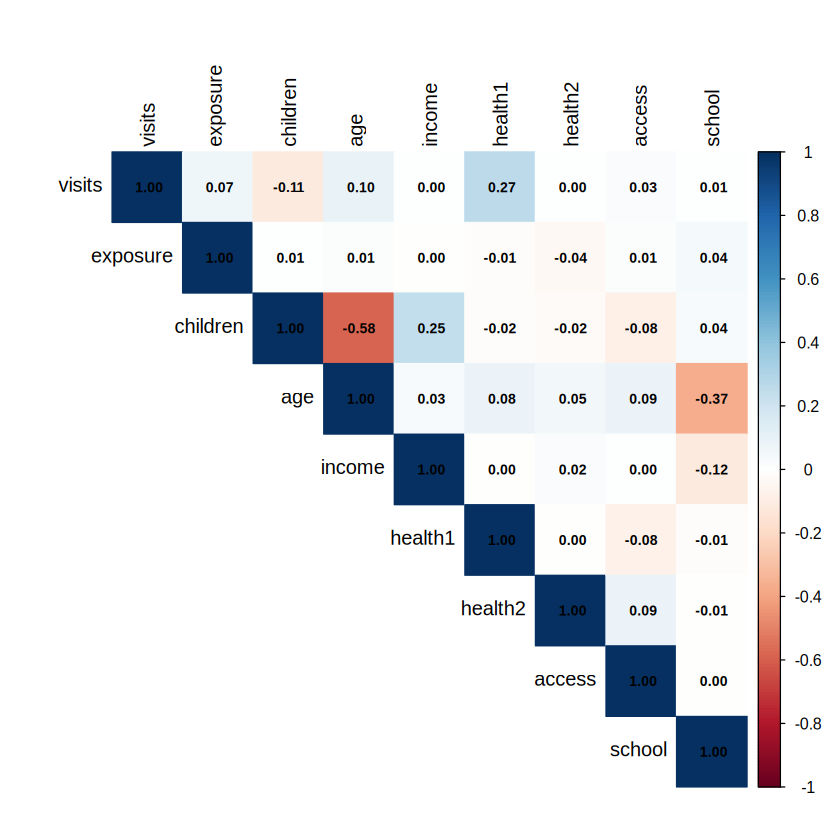

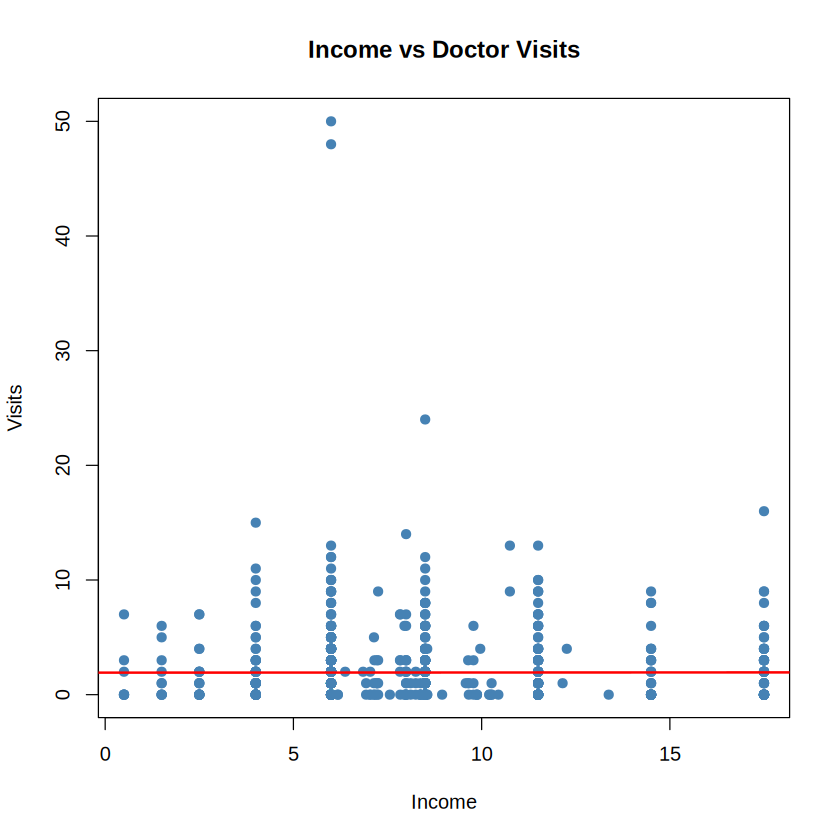


	Welch Two Sample t-test

data:  visits by enroll
t = 1.0456, df = 917.58, p-value = 0.296
alternative hypothesis: true difference in means between group no and group yes is not equal to 0
95 percent confidence interval:
 -0.1939439  0.6362605
sample estimates:
 mean in group no mean in group yes 
         2.039526          1.818367 


        
         afdc ssi
  female  469 374
  male     16 137



	Pearson's Chi-squared test with Yates' continuity correction

data:  tbl
X-squared = 103.99, df = 1, p-value < 2.2e-16


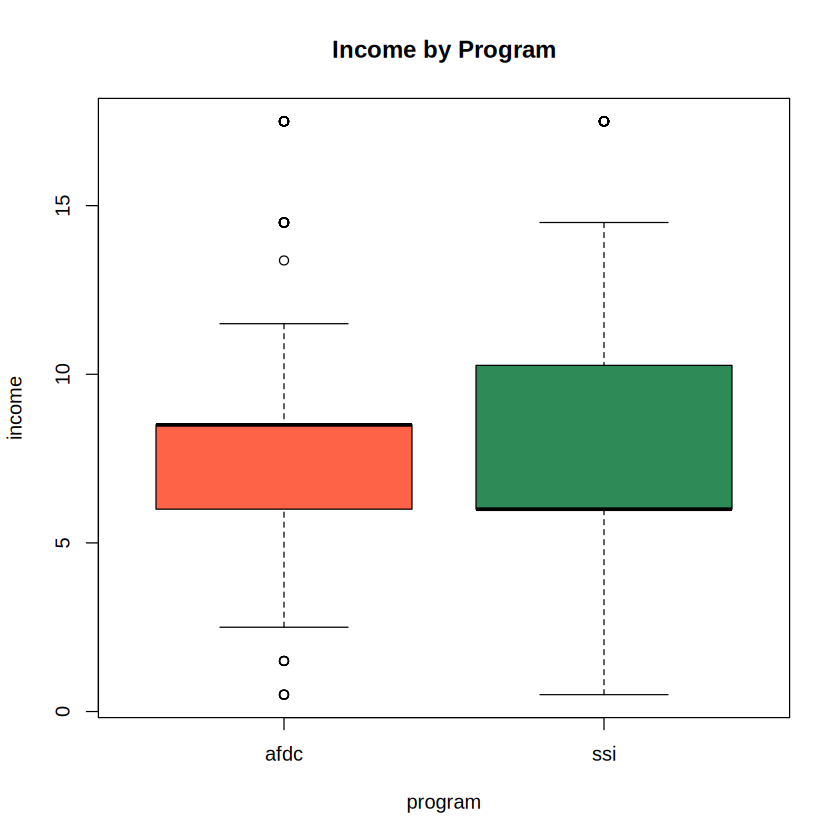


Call:
lm(formula = visits ~ income, data = data)

Residuals:
   Min     1Q Median     3Q    Max 
-1.941 -1.928 -0.931  1.063 48.072 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.92130    0.26256   7.318  5.2e-13 ***
income       0.00115    0.02931   0.039    0.969    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 3.356 on 994 degrees of freedom
Multiple R-squared:  1.55e-06,	Adjusted R-squared:  -0.001004 
F-statistic: 0.001541 on 1 and 994 DF,  p-value: 0.9687


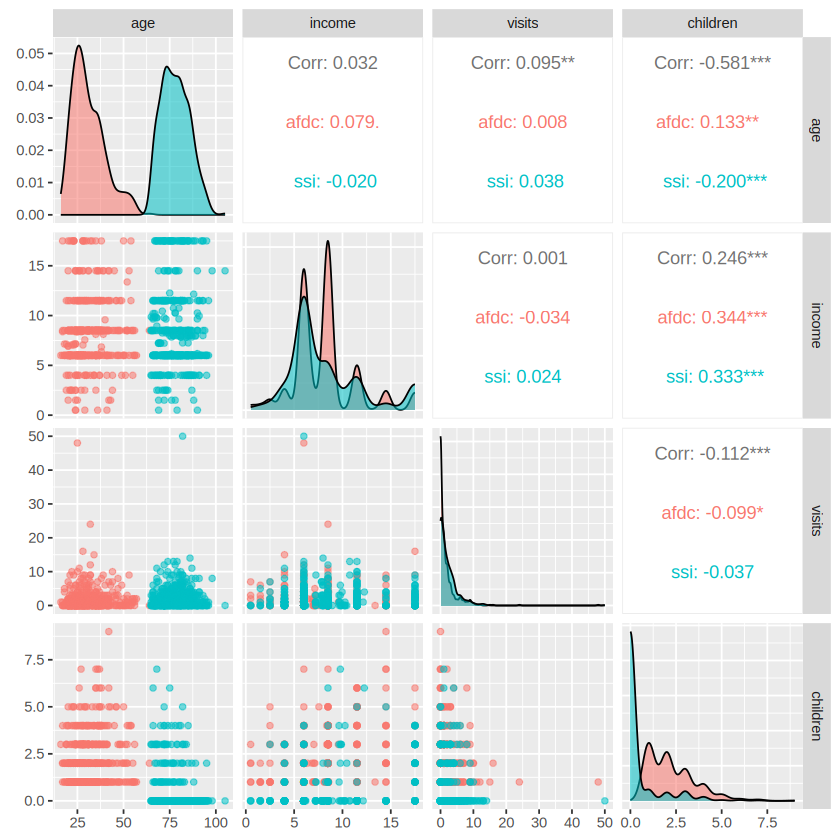

In [42]:
# Name   : Pranath
# Reg No : 23BDS0241
# Title  : 2-D (Bivariate) Statistical Analysis on Medicaid1986 Dataset

 install.packages(c("corrplot","GGally","ggplot2"))

library(corrplot)
library(GGally)
library(ggplot2)

data <- read.csv("https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Medicaid1986.csv")
head(data)

data$gender  <- factor(data$gender)
data$program <- factor(data$program)
data$enroll  <- factor(data$enroll)

numeric_cols <- c("visits","exposure","children","age","income","health1","health2","access","school")

cor_matrix <- cor(data[numeric_cols])
print(round(cor_matrix, 2))
corrplot(cor_matrix, method = "color", type = "upper", addCoef.col = "black",
         tl.col = "black", number.cex = 0.7)

cov(data$age, data$income)
cor.test(data$age, data$visits)

plot(data$income, data$visits, main = "Income vs Doctor Visits",
     xlab = "Income", ylab = "Visits", pch = 19, col = "steelblue")
abline(lm(visits ~ income, data = data), col = "red", lwd = 2)

boxplot(income ~ program, data = data, main = "Income by Program",
        col = c("tomato","seagreen"))
t.test(visits ~ enroll, data = data)

tbl <- table(data$gender, data$program)
print(tbl)
chisq.test(tbl)

ggpairs(data, columns = c("age","income","visits","children"),
         mapping = aes(color = program, alpha = 0.5))

model_2d <- lm(visits ~ income, data = data)
summary(model_2d)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



,rownames,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,1,0,100,1,24,14.500,0.495,-0.854,0.50,no,female,cauc,13,yes,afdc
2,2,1,90,3,19,6.000,0.520,-0.969,0.17,no,female,cauc,11,yes,afdc
3,3,0,106,4,17,8.377,-1.227,0.317,0.42,no,female,cauc,12,yes,afdc
4,4,0,114,2,29,6.000,-1.524,0.457,0.33,no,female,cauc,12,yes,afdc
5,5,11,115,1,26,8.500,0.173,-0.599,0.67,no,female,cauc,16,yes,afdc
6,6,3,102,1,22,6.000,-0.905,0.062,0.25,no,female,other,12,yes,afdc


HTML widgets cannot be represented in plain text (need html)

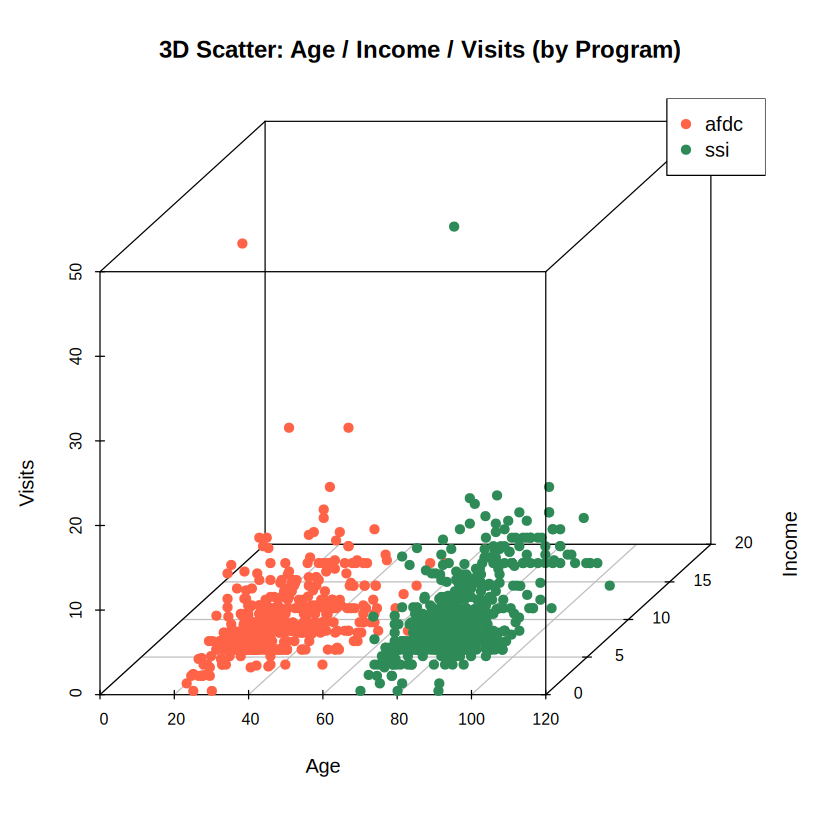


Call:
lm(formula = visits ~ age + income + children, data = data)

Residuals:
   Min     1Q Median     3Q    Max 
-2.610 -1.703 -0.967  0.665 47.698 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.743851   0.407592   4.278 2.06e-05 ***
age          0.005223   0.005336   0.979   0.3279    
income       0.021711   0.030814   0.705   0.4812    
children    -0.212524   0.091001  -2.335   0.0197 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 3.335 on 992 degrees of freedom
Multiple R-squared:  0.01448,	Adjusted R-squared:  0.0115 
F-statistic: 4.858 on 3 and 992 DF,  p-value: 0.002326


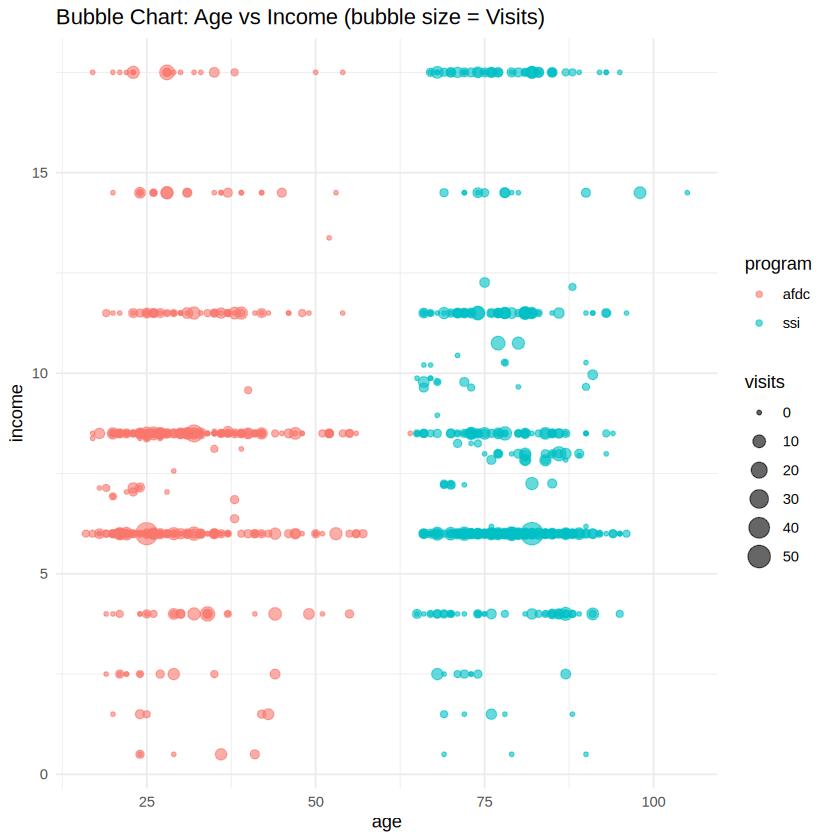

In [43]:
# Name   : Pranath
# Reg No : 23BDS0241
# Title  : 3-D (Trivariate) Statistical Analysis on Medicaid1986 Dataset

install.packages(c("scatterplot3d","plotly","ggplot2"))

library(scatterplot3d)
library(plotly)
library(ggplot2)

data <- read.csv("https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Medicaid1986.csv")
head(data)

data$program <- factor(data$program)

colors_3d <- c("tomato","seagreen")[as.numeric(data$program)]
scatterplot3d(data$age, data$income, data$visits,
              pch = 19, color = colors_3d,
              xlab = "Age", ylab = "Income", zlab = "Visits",
              main = "3D Scatter: Age / Income / Visits (by Program)")
legend("topright", legend = levels(data$program), col = c("tomato","seagreen"), pch = 19)

plot_ly(data, x = ~age, y = ~income, z = ~visits, color = ~program,
        type = "scatter3d", mode = "markers", marker = list(size = 3)) %>%
  layout(title = "Interactive 3D Scatter - Age / Income / Visits")

ggplot(data, aes(x = age, y = income, size = visits, color = program)) +
  geom_point(alpha = 0.6) +
  labs(title = "Bubble Chart: Age vs Income (bubble size = Visits)") +
  theme_minimal()

model_3d <- lm(visits ~ age + income + children, data = data)
summary(model_3d)

,rownames,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,1,0,100,1,24,14.500,0.495,-0.854,0.50,no,female,cauc,13,yes,afdc
2,2,1,90,3,19,6.000,0.520,-0.969,0.17,no,female,cauc,11,yes,afdc
3,3,0,106,4,17,8.377,-1.227,0.317,0.42,no,female,cauc,12,yes,afdc
4,4,0,114,2,29,6.000,-1.524,0.457,0.33,no,female,cauc,12,yes,afdc
5,5,11,115,1,26,8.500,0.173,-0.599,0.67,no,female,cauc,16,yes,afdc
6,6,3,102,1,22,6.000,-0.905,0.062,0.25,no,female,other,12,yes,afdc


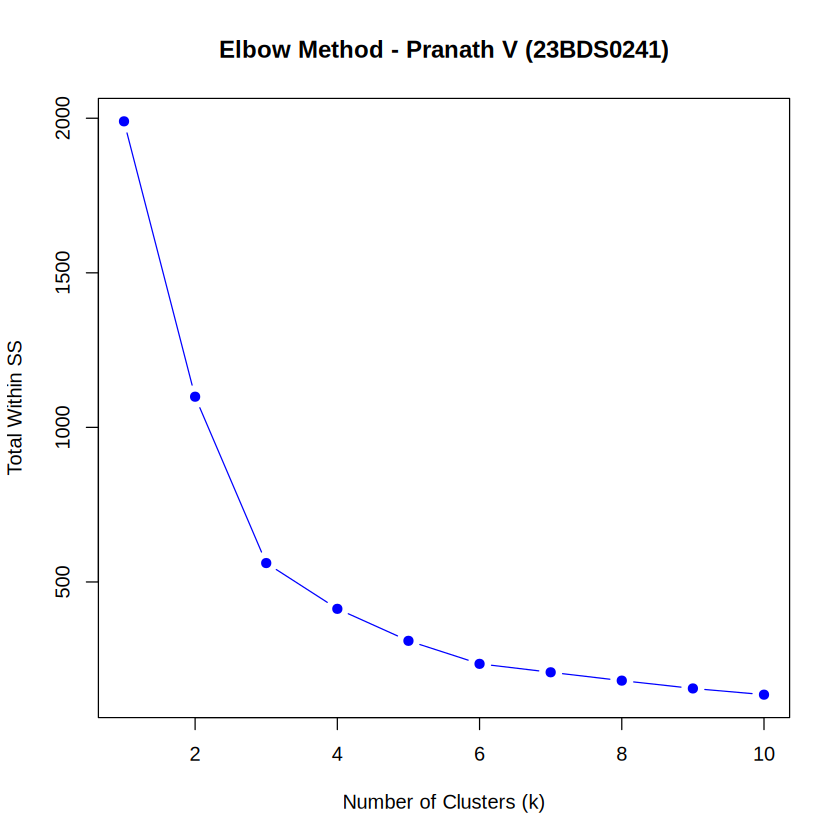

K-means clustering with 3 clusters of sizes 431, 173, 392

Cluster means:
         age     income
1 -0.9976165 -0.2346096
2  0.4266459  1.7340580
3  0.9085790 -0.5073349

Clustering vector:
  [1] 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 2 1 1 1 1 1 1 1 1 1
 [38] 1 1 1 1 1 1 1 1 1 1 1 1 3 1 1 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 3 1 1 1
 [75] 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 2 1
[112] 1 1 1 1 1 1 2 2 2 1 1 2 1 1 2 1 2 2 1 1 2 1 1 1 1 1 1 1 2 1 1 1 1 1 1 2 1
[149] 1 2 1 1 1 2 1 1 1 1 2 1 2 1 2 1 1 1 1 1 1 1 2 1 2 1 1 1 1 2 1 1 1 1 1 1 1
[186] 1 1 1 1 1 1 1 1 1 1 1 3 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 2 1 1 1 1 1 1 2 2 1
[223] 1 1 1 2 1 1 2 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
[260] 1 1 1 1 1 1 1 1 1 1 1 1 2 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1
[297] 1 3 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
[334] 3 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1 2 1 1 1 1 1 3 1 1
[371] 1 1 


  1   2   3 
431 173 392 

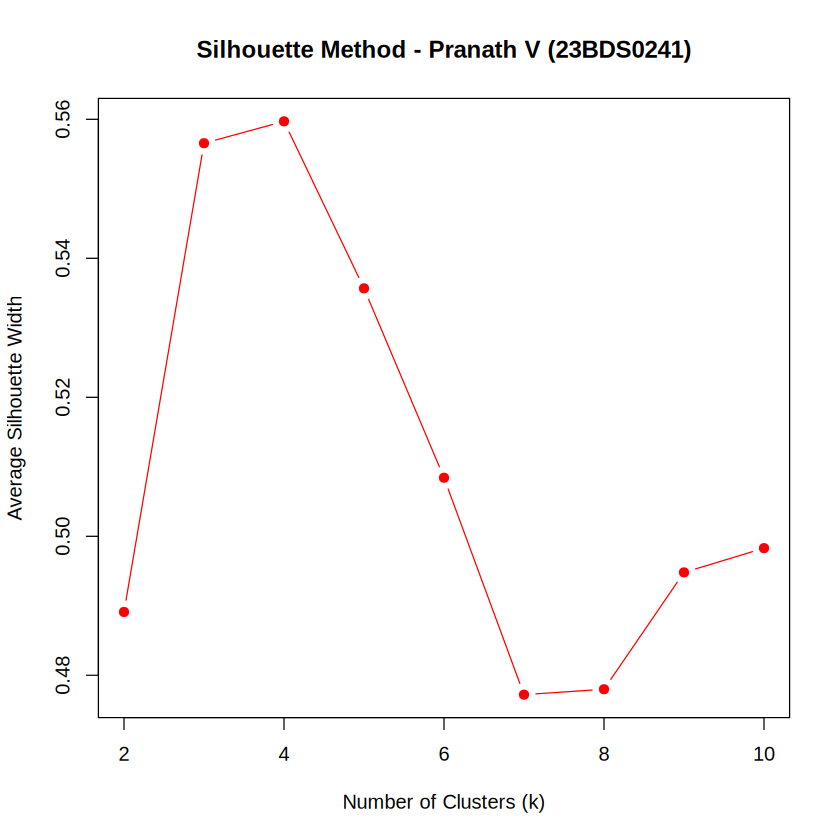

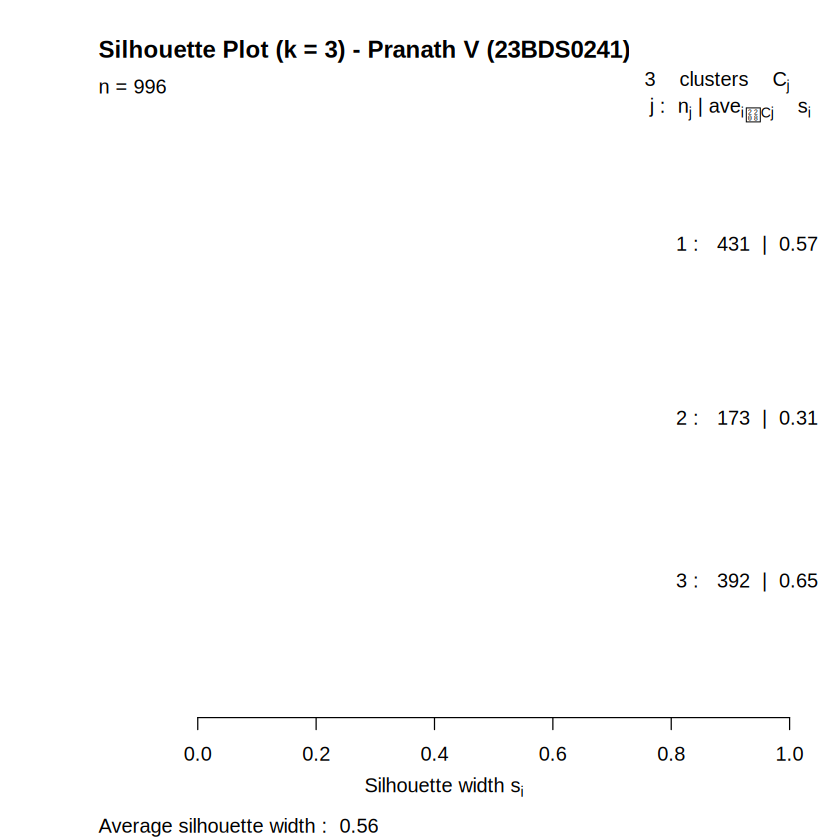

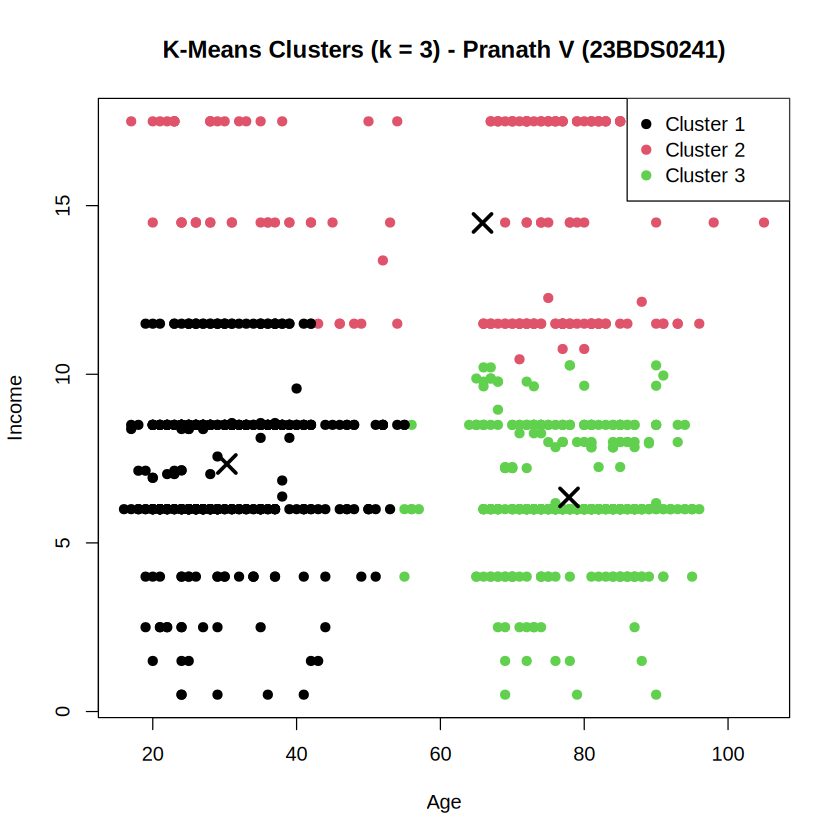

In [44]:
# Name   : Pranath V
# Reg No : 23BDS0241
# Title  : K-Means Clustering on Medicaid1986 Dataset

library(cluster)   # comes bundled with R, no install needed

data <- read.csv("https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Medicaid1986.csv")
head(data)

# Variables used for clustering
cluster_scaled <- scale(data[, c("age", "income")])

# Elbow method (WSS for k = 1 to 10)
set.seed(123)
wss <- sapply(1:10, function(k) kmeans(cluster_scaled, k, nstart = 25)$tot.withinss)
plot(1:10, wss, type = "b", pch = 19, col = "blue",
     xlab = "Number of Clusters (k)", ylab = "Total Within SS",
     main = "Elbow Method - Pranath V (23BDS0241)")

# Silhouette method (k = 2 to 10)
d <- dist(cluster_scaled)
sil_avg <- sapply(2:10, function(k) {
  km <- kmeans(cluster_scaled, k, nstart = 25)
  mean(silhouette(km$cluster, d)[, 3])
})
plot(2:10, sil_avg, type = "b", pch = 19, col = "red",
     xlab = "Number of Clusters (k)", ylab = "Average Silhouette Width",
     main = "Silhouette Method - Pranath V (23BDS0241)")

# Final K-Means (k = 3)
set.seed(123)
km_out <- kmeans(cluster_scaled, centers = 3, nstart = 25)
print(km_out)
table(km_out$cluster)
data$kmeans_cluster <- factor(km_out$cluster)

# Silhouette plot for k = 3
sil <- silhouette(km_out$cluster, d)
plot(sil, col = 1:3, main = "Silhouette Plot (k = 3) - Pranath V (23BDS0241)")

# Cluster plot (original scale)
plot(data$age, data$income, col = data$kmeans_cluster, pch = 19,
     xlab = "Age", ylab = "Income",
     main = "K-Means Clusters (k = 3) - Pranath V (23BDS0241)")
points(km_out$centers[, 1] * sd(data$age) + mean(data$age),
       km_out$centers[, 2] * sd(data$income) + mean(data$income),
       pch = 4, cex = 2, lwd = 3)
legend("topright", legend = paste("Cluster", 1:3), col = 1:3, pch = 19)

,rownames,visits,exposure,children,age,income,health1,health2,access,married,gender,ethnicity,school,enroll,program
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,1,0,100,1,24,14.500,0.495,-0.854,0.50,no,female,cauc,13,yes,afdc
2,2,1,90,3,19,6.000,0.520,-0.969,0.17,no,female,cauc,11,yes,afdc
3,3,0,106,4,17,8.377,-1.227,0.317,0.42,no,female,cauc,12,yes,afdc
4,4,0,114,2,29,6.000,-1.524,0.457,0.33,no,female,cauc,12,yes,afdc
5,5,11,115,1,26,8.500,0.173,-0.599,0.67,no,female,cauc,16,yes,afdc
6,6,3,102,1,22,6.000,-0.905,0.062,0.25,no,female,other,12,yes,afdc



  1   2   3 
104 443 449 

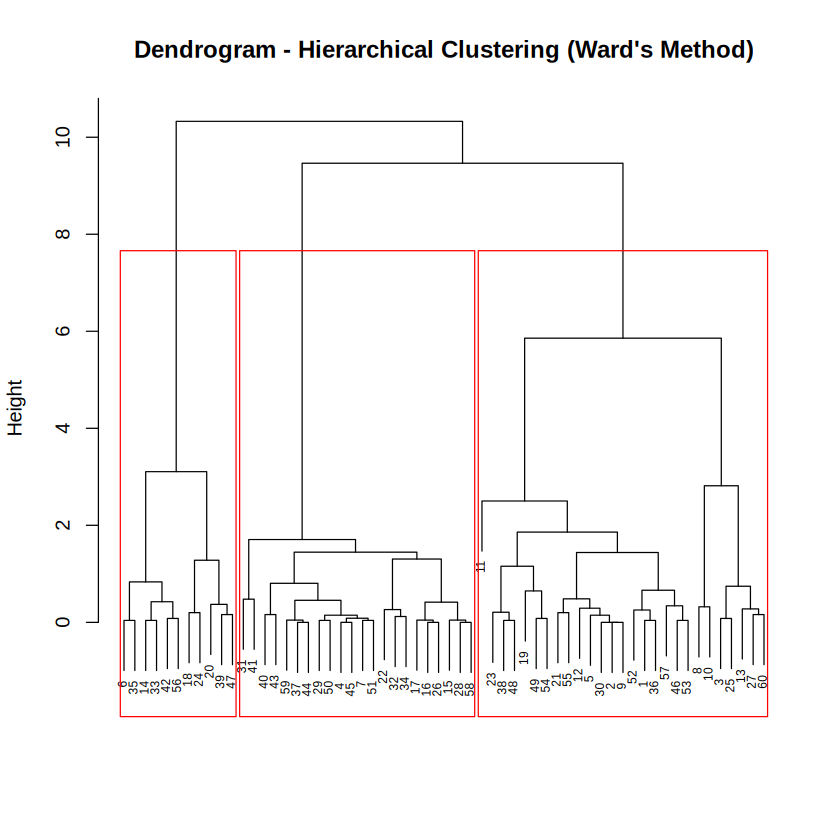

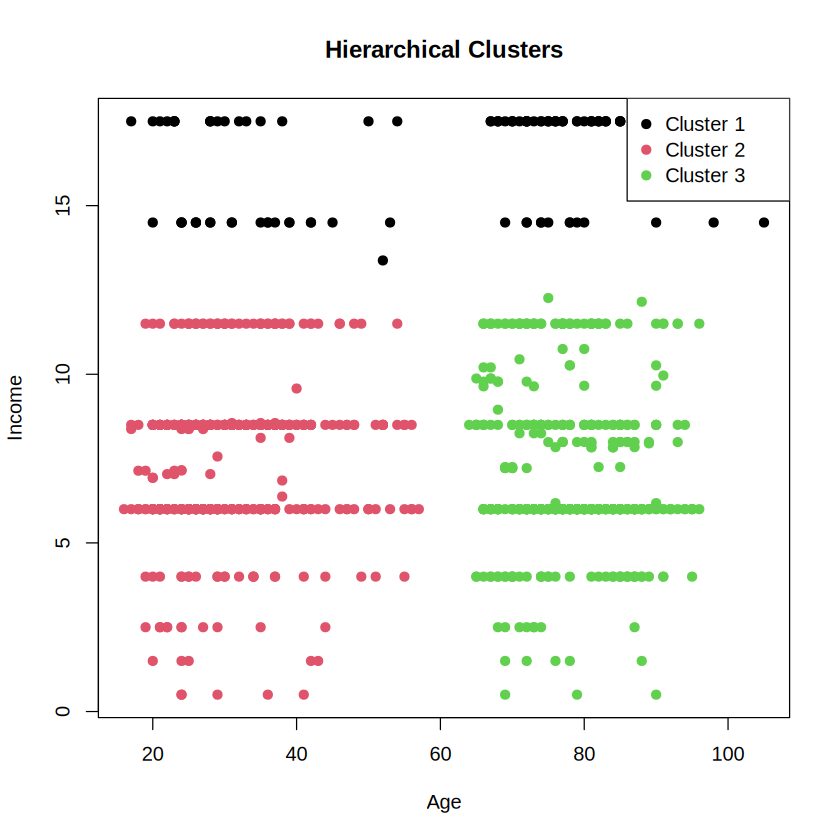

In [45]:
# Name   : Pranath
# Reg No : 23BDS0241
#Title  : Hierarchical Clustering on Medicaid1986 Dataset

data <- read.csv("https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Medicaid1986.csv")
head(data)

# Using only two variables (age, income) instead of all columns
cluster_vars   <- data[, c("age", "income")]
cluster_scaled <- scale(cluster_vars)

set.seed(123)
sample_idx <- sample(1:nrow(cluster_scaled), 60)
hc_sample  <- cluster_scaled[sample_idx, ]

dist_matrix <- dist(hc_sample, method = "euclidean")
hc_out      <- hclust(dist_matrix, method = "ward.D2")

plot(hc_out, main = "Dendrogram - Hierarchical Clustering (Ward's Method)",
     xlab = "", sub = "", cex = 0.6)
rect.hclust(hc_out, k = 3, border = "red")

dist_full <- dist(cluster_scaled, method = "euclidean")
hc_full   <- hclust(dist_full, method = "ward.D2")
data$hc_cluster <- factor(cutree(hc_full, k = 3))
table(data$hc_cluster)

plot(data$age, data$income, col = data$hc_cluster, pch = 19,
     xlab = "Age", ylab = "Income", main = "Hierarchical Clusters")
legend("topright", legend = paste("Cluster", 1:3), col = 1:3, pch = 19)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘xts’, ‘TTR’, ‘quadprog’, ‘quantmod’


Warning message in install.packages(c("forecast", "tseries")):
“installation of package ‘forecast’ had non-zero exit status”
Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 



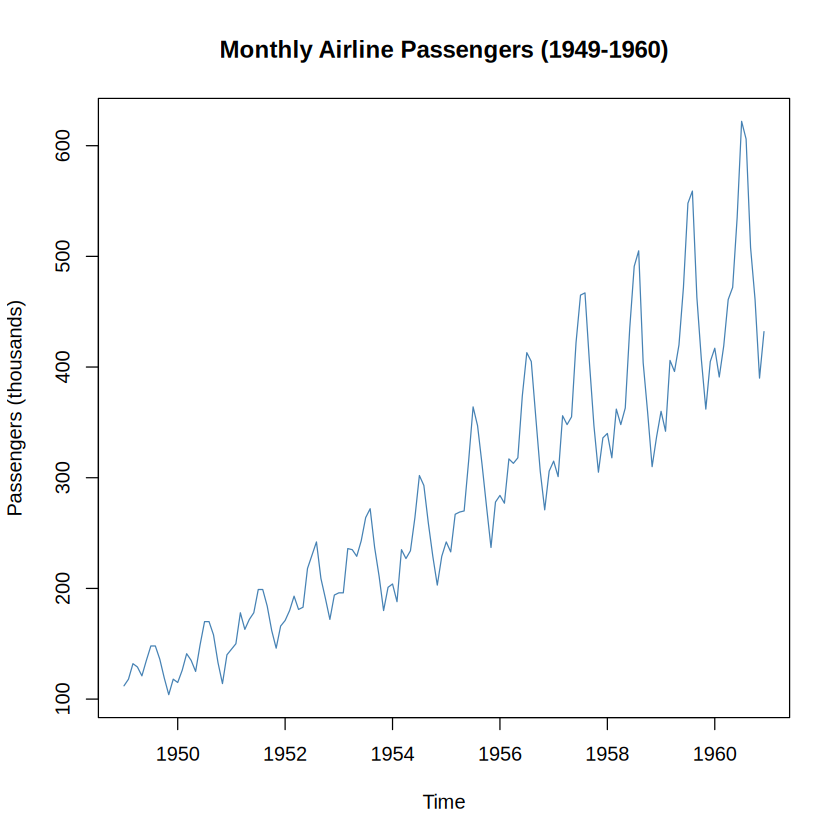

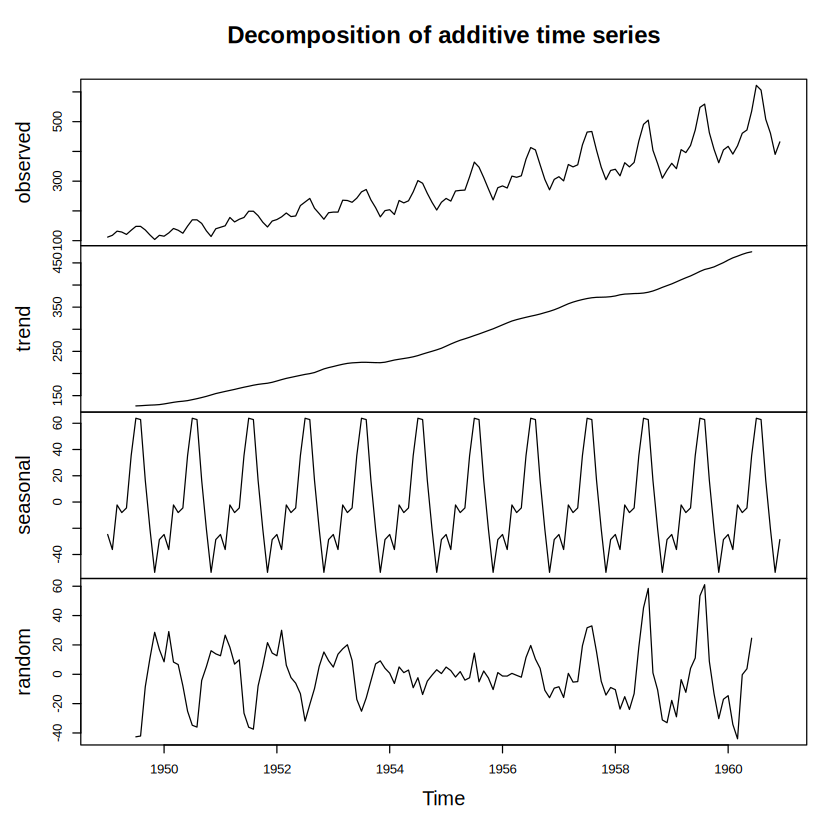

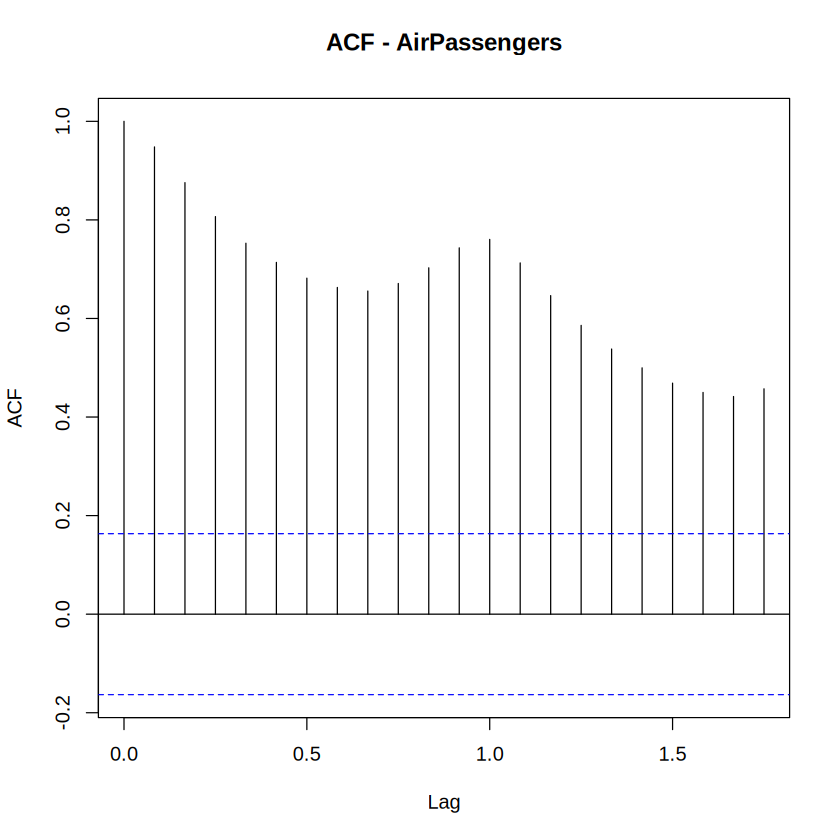

Warning message in adf.test(ts_data):
“p-value smaller than printed p-value”



	Augmented Dickey-Fuller Test

data:  ts_data
Dickey-Fuller = -7.3186, Lag order = 5, p-value = 0.01
alternative hypothesis: stationary


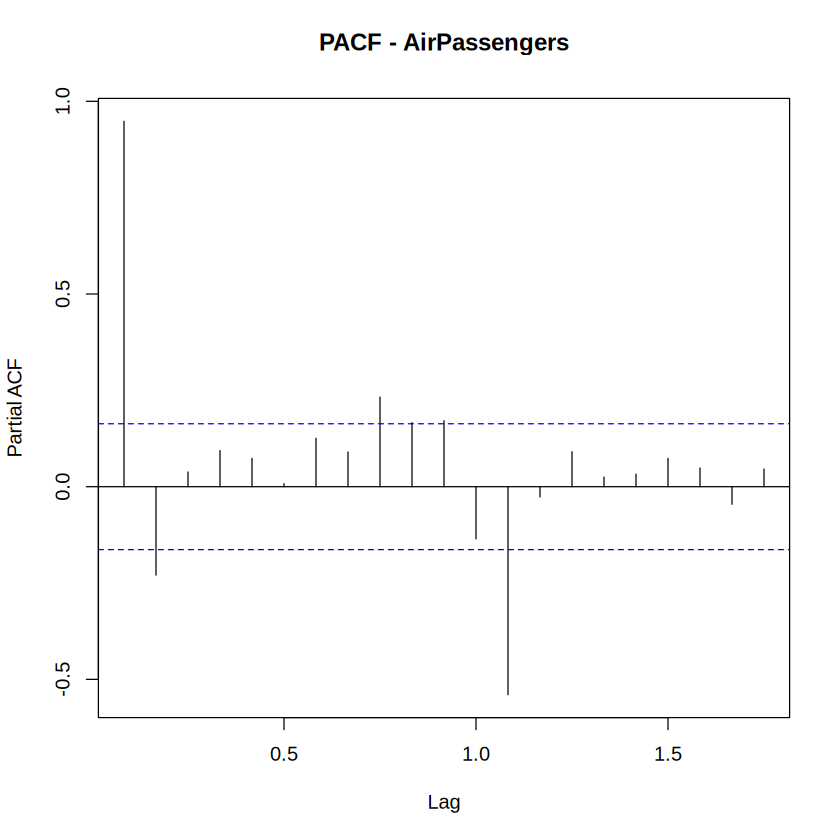

Warning message in adf.test(ts_diff):
“p-value smaller than printed p-value”



	Augmented Dickey-Fuller Test

data:  ts_diff
Dickey-Fuller = -7.0177, Lag order = 5, p-value = 0.01
alternative hypothesis: stationary


Series: ts_data 
ARIMA(2,1,1)(0,1,0)[12] 

Coefficients:
         ar1     ar2      ma1
      0.5960  0.2143  -0.9819
s.e.  0.0888  0.0880   0.0292

sigma^2 = 132.3:  log likelihood = -504.92
AIC=1017.85   AICc=1018.17   BIC=1029.35

Training set error measures:
                   ME     RMSE     MAE       MPE     MAPE     MASE         ACF1
Training set 1.342299 10.84619 7.86754 0.4206976 2.800458 0.245628 -0.001248475

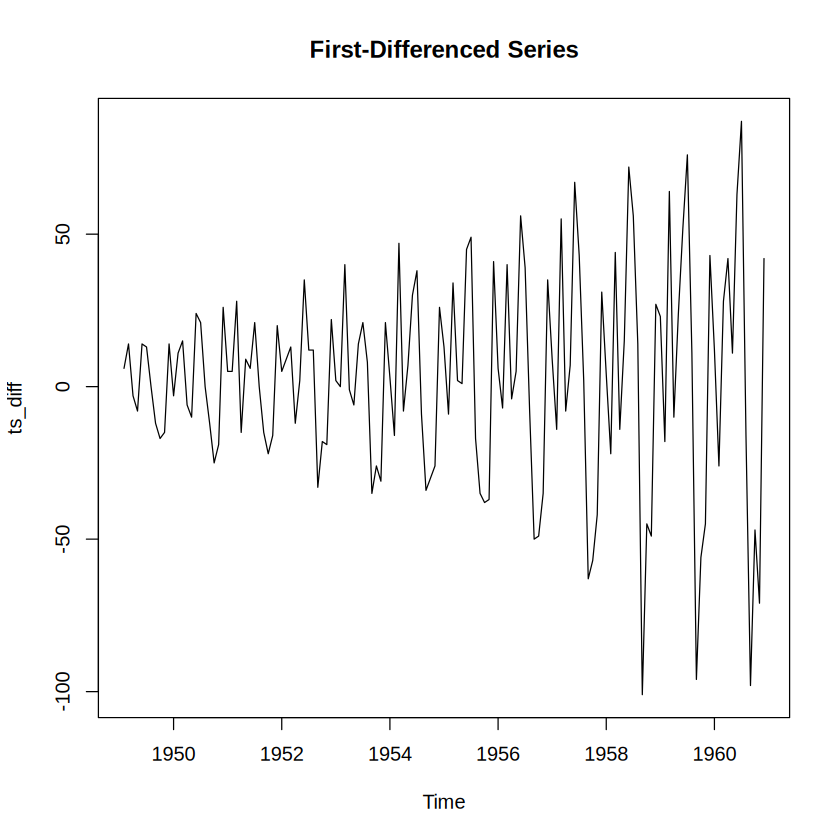

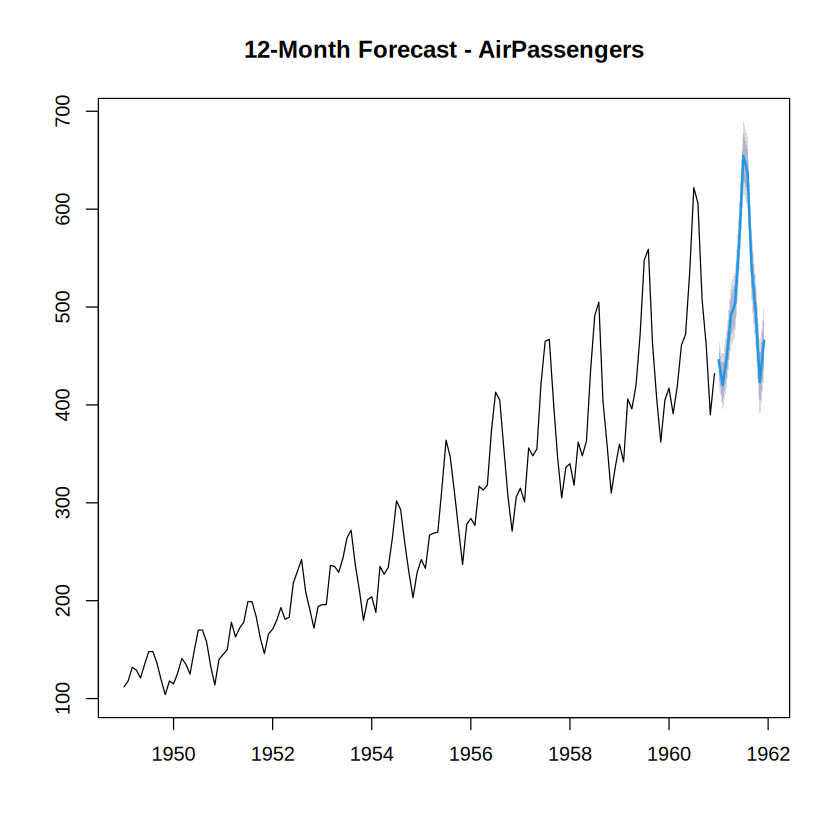

In [46]:
# Name   : Pranath
# Reg No : 23BDS0241
# Title  : Time Series Analysis (AirPassengers Dataset)
# Note   : Medicaid1986 has no date/time field, so the built-in AirPassengers
#          series is used here to demonstrate time series methods.

install.packages(c("forecast","tseries"))

library(forecast)
library(tseries)

data("AirPassengers")
ts_data <- AirPassengers

plot(ts_data, main = "Monthly Airline Passengers (1949-1960)",
     ylab = "Passengers (thousands)", col = "steelblue")

decomp <- decompose(ts_data)
plot(decomp)

acf(ts_data, main = "ACF - AirPassengers")
pacf(ts_data, main = "PACF - AirPassengers")

adf.test(ts_data)

ts_diff <- diff(ts_data, differences = 1)
plot(ts_diff, main = "First-Differenced Series")
adf.test(ts_diff)

model_arima <- auto.arima(ts_data)
summary(model_arima)

forecast_vals <- forecast(model_arima, h = 12)
plot(forecast_vals, main = "12-Month Forecast - AirPassengers")

Pranath V - 23BDS0241 - Module 6: PCA

'data.frame':	996 obs. of  15 variables:
 $ rownames : int  1 2 3 4 5 6 7 8 9 10 ...
 $ visits   : int  0 1 0 0 11 3 0 6 1 0 ...
 $ exposure : int  100 90 106 114 115 102 92 92 117 101 ...
 $ children : int  1 3 4 2 1 1 2 1 1 1 ...
 $ age      : int  24 19 17 29 26 22 24 21 21 24 ...
 $ income   : num  14.5 6 8.38 6 8.5 ...
 $ health1  : num  0.495 0.52 -1.227 -1.524 0.173 ...
 $ health2  : num  -0.854 -0.969 0.317 0.457 -0.599 0.062 0.202 -0.981 0.317 -0.562 ...
 $ access   : num  0.5 0.17 0.42 0.33 0.67 0.25 0.5 0.67 0.25 0.67 ...
 $ married  : chr  "no" "no" "no" "no" ...
 $ gender   : chr  "female" "female" "female" "female" ...
 $ ethnicity: chr  "cauc" "cauc" "cauc" "cauc" ...
 $ school   : int  13 11 12 12 16 12 11 11 12 15 ...
 $ enroll   : chr  "yes" "yes" "yes" "yes" ...
 $ program  : chr  "afdc" "afdc" "afdc" "afdc" ...
Importance of components:
                          PC1    PC2    PC3    PC4    PC5     PC6     PC7
Standard deviation

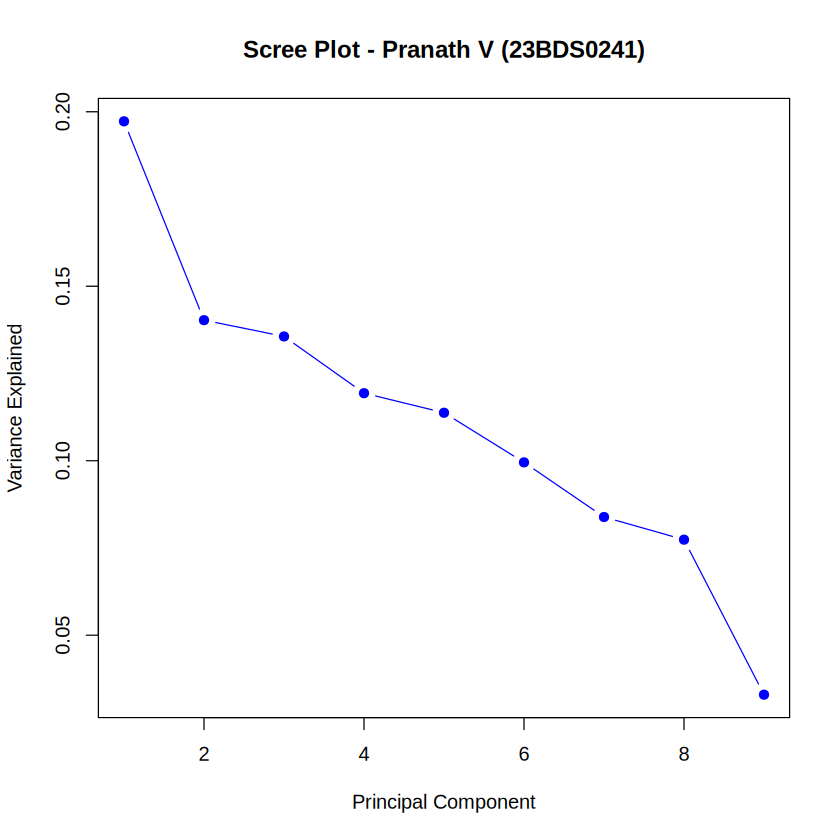

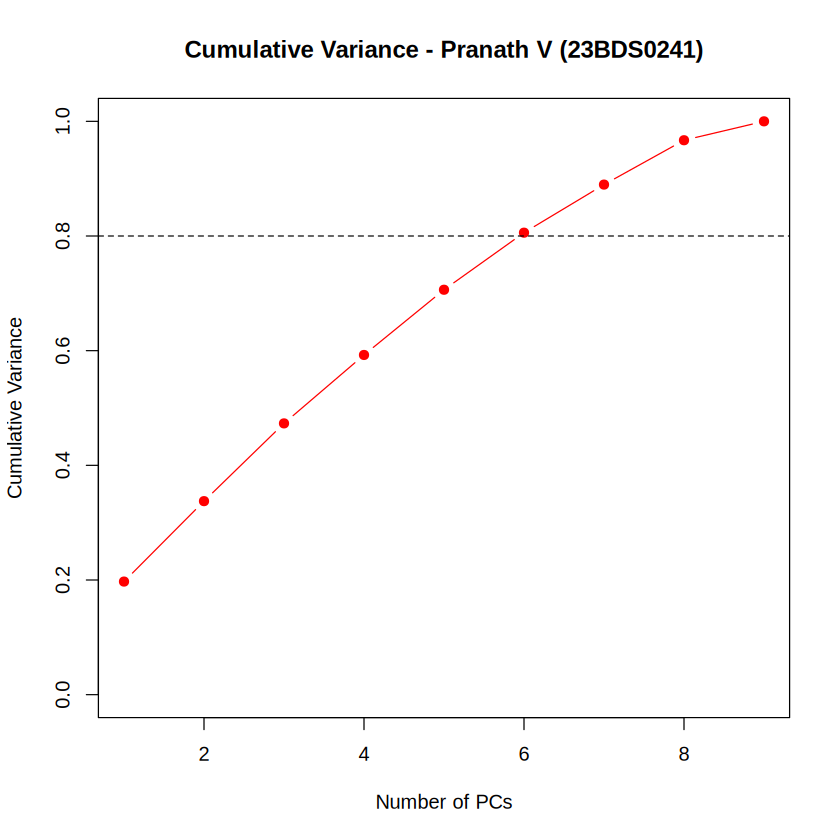

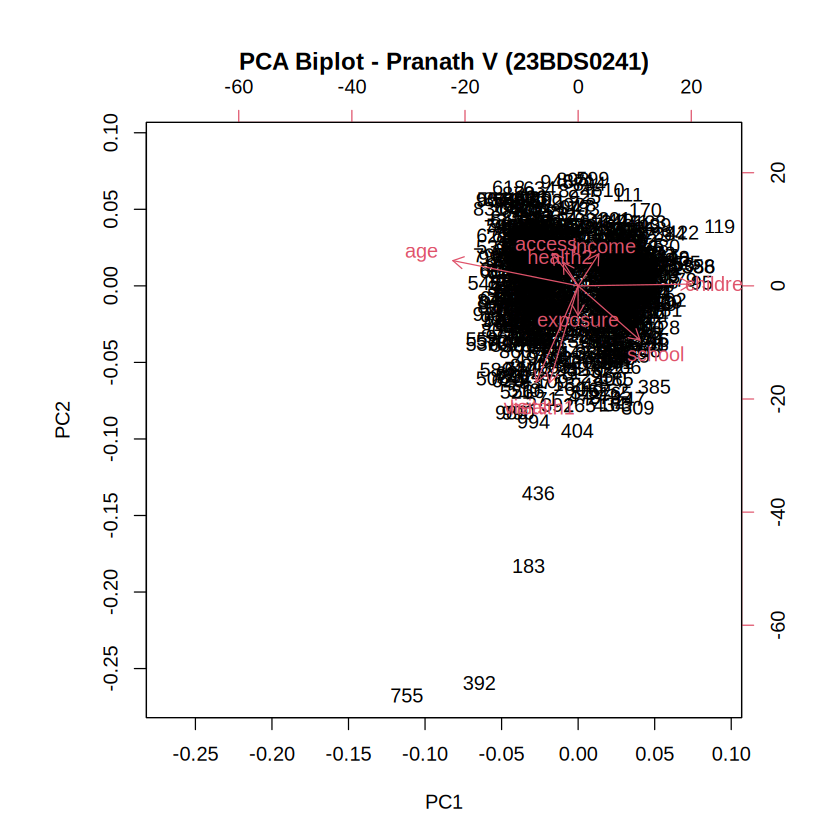

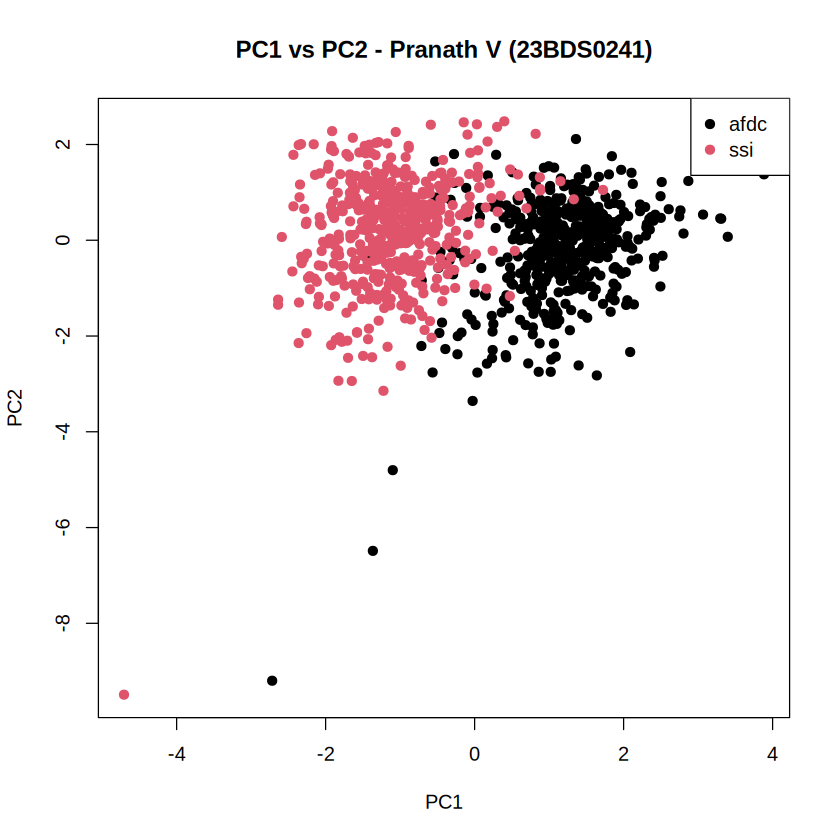

In [47]:
# Name: Pranath V | Reg No: 23BDS0241
# Module 6: Principal Component Analysis (PCA) - Medicaid1986

url <- "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Medicaid1986.csv"
df  <- read.csv(url)
df  <- na.omit(df)
cat("Pranath V - 23BDS0241 - Module 6: PCA\n\n")
str(df)

# numeric columns only
num <- df[, c("visits","exposure","children","age","income",
              "health1","health2","access","school")]

# PCA with scaling
pca <- prcomp(num, center = TRUE, scale. = TRUE)
print(summary(pca))

# variance explained
var_exp <- pca$sdev^2 / sum(pca$sdev^2)
cum_exp <- cumsum(var_exp)

var_table <- data.frame(PC = paste0("PC", 1:length(var_exp)),
                        Variance   = round(var_exp, 4),
                        Cumulative = round(cum_exp, 4))
print(var_table)

# loadings
cat("\nLoadings:\n")
print(round(pca$rotation, 3))

# scree plot
plot(var_exp, type = "b", pch = 19, col = "blue",
     xlab = "Principal Component", ylab = "Variance Explained",
     main = "Scree Plot - Pranath V (23BDS0241)")

# cumulative variance plot
plot(cum_exp, type = "b", pch = 19, col = "red", ylim = c(0, 1),
     xlab = "Number of PCs", ylab = "Cumulative Variance",
     main = "Cumulative Variance - Pranath V (23BDS0241)")
abline(h = 0.8, lty = 2)

# biplot
biplot(pca, main = "PCA Biplot - Pranath V (23BDS0241)")

# PC1 vs PC2 coloured by program
plot(pca$x[,1], pca$x[,2], col = as.factor(df$program), pch = 19,
     xlab = "PC1", ylab = "PC2",
     main = "PC1 vs PC2 - Pranath V (23BDS0241)")
legend("topright", legend = levels(as.factor(df$program)),
       col = 1:length(levels(as.factor(df$program))), pch = 19)

Pranath V - 23BDS0241 - Module 7: Logistic Regression


Call:
glm(formula = enroll ~ visits + exposure + children + age + income + 
    health1 + health2 + access + married + gender + ethnicity + 
    school + program, family = binomial, data = train)

Coefficients:
                Estimate Std. Error z value Pr(>|z|)    
(Intercept)    -1.966926   0.986020  -1.995   0.0461 *  
visits         -0.029909   0.025898  -1.155   0.2481    
exposure        0.003674   0.008365   0.439   0.6605    
children       -0.059497   0.073172  -0.813   0.4162    
age             0.009998   0.010135   0.986   0.3239    
income          0.017244   0.023402   0.737   0.4612    
health1        -0.040077   0.061226  -0.655   0.5127    
health2         0.057203   0.108063   0.529   0.5966    
access          2.204001   0.436114   5.054 4.33e-07 ***
marriedyes      0.058242   0.214762   0.271   0.7862    
gendermale     -0.208220   0.245660  -0.848   0.3967    
ethnicityother  0.091985   0.179119   0.514   0.6

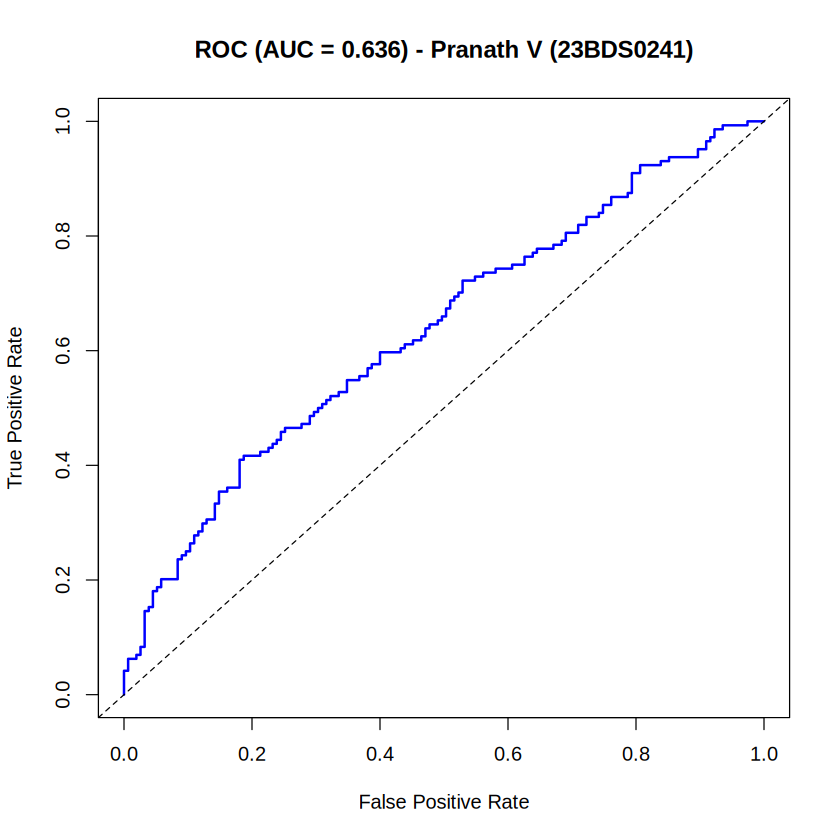

In [48]:
# Name: Pranath V | Reg No: 23BDS0241
# Module 7: Classification - Logistic Regression - Medicaid1986

url <- "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Medicaid1986.csv"
df  <- read.csv(url)
df  <- na.omit(df)
cat("Pranath V - 23BDS0241 - Module 7: Logistic Regression\n\n")

# prepare data
df$enroll    <- ifelse(df$enroll == "yes", 1, 0)   # target: 1 = enrolled
df$married   <- as.factor(df$married)
df$gender    <- as.factor(df$gender)
df$ethnicity <- as.factor(df$ethnicity)
df$program   <- as.factor(df$program)
df$rownames  <- NULL

# train/test split (70/30)
set.seed(23)
idx   <- sample(1:nrow(df), 0.7 * nrow(df))
train <- df[idx, ]
test  <- df[-idx, ]

# model
model <- glm(enroll ~ visits + exposure + children + age + income +
               health1 + health2 + access + married + gender +
               ethnicity + school + program,
             data = train, family = binomial)
print(summary(model))

# odds ratios
cat("\nOdds Ratios:\n")
print(round(exp(coef(model)), 3))

# predict
prob <- predict(model, newdata = test, type = "response")
pred <- ifelse(prob > 0.5, 1, 0)

# confusion matrix (forced 2x2 so it never breaks)
cm <- table(Actual    = factor(test$enroll, levels = c(0, 1)),
            Predicted = factor(pred,        levels = c(0, 1)))
cat("\nConfusion Matrix:\n")
print(cm)

# metrics
tp <- cm["1","1"]; fp <- cm["0","1"]; fn <- cm["1","0"]
acc       <- sum(diag(cm)) / sum(cm)
precision <- ifelse(tp + fp == 0, 0, tp / (tp + fp))
recall    <- ifelse(tp + fn == 0, 0, tp / (tp + fn))
f1        <- ifelse(precision + recall == 0, 0,
                    2 * precision * recall / (precision + recall))

cat("\nAccuracy :", round(acc, 4))
cat("\nPrecision:", round(precision, 4))
cat("\nRecall   :", round(recall, 4))
cat("\nF1 Score :", round(f1, 4), "\n")

# ROC curve + AUC
ord <- order(prob, decreasing = TRUE)
y   <- test$enroll[ord]
tpr <- cumsum(y) / sum(y)
fpr <- cumsum(1 - y) / sum(1 - y)
auc <- sum(diff(c(0, fpr)) * tpr)
plot(c(0, fpr), c(0, tpr), type = "l", col = "blue", lwd = 2,
     xlab = "False Positive Rate", ylab = "True Positive Rate",
     main = paste0("ROC (AUC = ", round(auc, 3), ") - Pranath V (23BDS0241)"))
abline(0, 1, lty = 2)
cat("AUC:", round(auc, 4), "\n")